# Wellness Tourism Package: Who Will Buy? (Customer Prediction)

**Problem statement.** A travel company is launching a new **Wellness Tourism Package**. Its sales team phones customers one by one, but only about **1 in 5 customers (18.8%) says yes**. Calling everyone wastes time and money. The company wants a model that looks at what it already knows about a customer and says **how likely that person is to buy**, so the team can call the best customers first.

**Goal.**
1. Predict `ProdTaken` (1 = bought the package, 0 = did not).
2. Find out which customer facts matter most.
3. Turn the scores into simple priority groups (**A, B, C**) the sales team can use.
4. Show how many customers must be called to win most of the sales.

**Dataset.** 4,888 customers x 20 columns (18 after cleaning): age, income, job level (`Designation`), passport, marital status, city tier, trips per year, sales-call details and more.

**Words used in this notebook (a 12-year-old's glossary).**

| Word | Simple meaning |
|---|---|
| **Buyer / non-buyer** | A customer who said yes / said no |
| **Train set / test set** | Train = the questions we **practise** with. Test = a **final exam** we open only once, at the end |
| **Cross-validation (CV)** | Several **practice tests**. We split the training data in 5 parts, practise on 4, check on 1, and repeat. The average is a fair score |
| **Accuracy** | How many answers were right out of all. It can fool us when most people say "no" |
| **Recall** | Of all the real buyers, how many did we **find**? |
| **Precision** | Of the people we **called**, how many really bought? |
| **ROC-AUC** | A score from 0.5 (guessing) to 1.0 (perfect) for how well the model puts buyers **above** non-buyers in the list |
| **Overfitting** | Memorising the practice questions instead of learning the idea, so the model does worse on new questions |
| **Leakage** | Accidentally giving the model the answer (or a peek at the exam) so the score looks better than it should |

**How we judge success.** Because most customers say "no", a model that always says "no" is already about 81% accurate and finds nobody. So we judge the model by **AUC, recall, precision and how many buyers sit in the top of the list**, not by accuracy alone.

**Workflow.** Load and check -> Clean -> Explore -> Split and prepare -> Simple baseline -> Fix imbalance -> Explain the factors -> Compare models -> Check for repeated customers -> Tune and pick the final model -> Test once -> Priority groups and call plan -> Overfitting and leakage checks -> Who to target -> Save the model.

*Every result is followed by an **Inference** box that explains it in plain words.*

---
## Part 1: Load the data and take a first look
Import the tools, read the file and see its size and column types.

In [1]:
import warnings
import pandas as pd
import numpy as np

warnings.filterwarnings("ignore")


In [2]:
df = pd.read_csv("Travel.csv")   # change to the path of your Travel.csv
df.head()

,CustomerID,ProdTaken,Age,TypeofContact,CityTier,DurationOfPitch,Occupation,Gender,NumberOfPersonVisiting,NumberOfFollowups,ProductPitched,PreferredPropertyStar,MaritalStatus,NumberOfTrips,Passport,PitchSatisfactionScore,OwnCar,NumberOfChildrenVisiting,Designation,MonthlyIncome
0,200000,1,41.0,Self Enquiry,3,6.0,Salaried,Female,3,3.0,Deluxe,3.0,Single,1.0,1,2,1,0.0,Manager,20993.0
1,200001,0,49.0,Company Invited,1,14.0,Salaried,Male,3,4.0,Deluxe,4.0,Divorced,2.0,0,3,1,2.0,Manager,20130.0
2,200002,1,37.0,Self Enquiry,1,8.0,Free Lancer,Male,3,4.0,Basic,3.0,Single,7.0,1,3,0,0.0,Executive,17090.0
3,200003,0,33.0,Company Invited,1,9.0,Salaried,Female,2,3.0,Basic,3.0,Divorced,2.0,1,5,1,1.0,Executive,17909.0
4,200004,0,NaN,Self Enquiry,1,8.0,Small Business,Male,2,3.0,Basic,4.0,Divorced,1.0,0,5,1,0.0,Executive,18468.0


In [3]:
# Clean column names: strip spaces
df.columns = df.columns.str.strip()

# Peek at the first 5 rows (show all columns)
pd.set_option("display.max_columns", None)

# List all column names
print("\nColumn names:")
print(df.columns.tolist())

# Quick size check
print(f"\nShape: {df.shape[0]} rows x {df.shape[1]} columns")

# How balanced is the target?
print("\n=== TARGET: ProdTaken ===")
print(df["ProdTaken"].value_counts())
print((df["ProdTaken"].value_counts(normalize=True) * 100).round(1))
df.head()


Column names:
['CustomerID', 'ProdTaken', 'Age', 'TypeofContact', 'CityTier', 'DurationOfPitch', 'Occupation', 'Gender', 'NumberOfPersonVisiting', 'NumberOfFollowups', 'ProductPitched', 'PreferredPropertyStar', 'MaritalStatus', 'NumberOfTrips', 'Passport', 'PitchSatisfactionScore', 'OwnCar', 'NumberOfChildrenVisiting', 'Designation', 'MonthlyIncome']

Shape: 4888 rows x 20 columns

=== TARGET: ProdTaken ===
ProdTaken
0    3968
1     920
Name: count, dtype: int64
ProdTaken
0    81.2
1    18.8
Name: proportion, dtype: float64


,CustomerID,ProdTaken,Age,TypeofContact,CityTier,DurationOfPitch,Occupation,Gender,NumberOfPersonVisiting,NumberOfFollowups,ProductPitched,PreferredPropertyStar,MaritalStatus,NumberOfTrips,Passport,PitchSatisfactionScore,OwnCar,NumberOfChildrenVisiting,Designation,MonthlyIncome
0,200000,1,41.0,Self Enquiry,3,6.0,Salaried,Female,3,3.0,Deluxe,3.0,Single,1.0,1,2,1,0.0,Manager,20993.0
1,200001,0,49.0,Company Invited,1,14.0,Salaried,Male,3,4.0,Deluxe,4.0,Divorced,2.0,0,3,1,2.0,Manager,20130.0
2,200002,1,37.0,Self Enquiry,1,8.0,Free Lancer,Male,3,4.0,Basic,3.0,Single,7.0,1,3,0,0.0,Executive,17090.0
3,200003,0,33.0,Company Invited,1,9.0,Salaried,Female,2,3.0,Basic,3.0,Divorced,2.0,1,5,1,1.0,Executive,17909.0
4,200004,0,NaN,Self Enquiry,1,8.0,Small Business,Male,2,3.0,Basic,4.0,Divorced,1.0,0,5,1,0.0,Executive,18468.0


In [4]:
# Data types and non-null counts for every column
print("=== DATA TYPES & NON-NULL COUNTS ===")
df.info()

# Count missing values per column
missing = df.isnull().sum()
print("\n=== MISSING VALUES ===")
print(missing[missing > 0])

# Missing as a percentage of all rows
print("\n=== MISSING % ===")
print((missing[missing > 0] / len(df) * 100).round(2))

# Duplicate rows and duplicate customer IDs
print(f"\nDuplicate rows: {df.duplicated().sum()}")
print(f"Duplicate CustomerIDs: {df['CustomerID'].duplicated().sum()}")

# Summary statistics for numeric columns
print("\n=== NUMERIC SUMMARY ===")
print(df.describe().round(2).T)

# Unique values in the text columns (to spot messy labels)
for col in df.select_dtypes(exclude="number").columns:
    print(f"\n=== {col} ===")
    print(df[col].value_counts(dropna=False))

=== DATA TYPES & NON-NULL COUNTS ===
<class 'pandas.DataFrame'>
RangeIndex: 4888 entries, 0 to 4887
Data columns (total 20 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   CustomerID                4888 non-null   int64  
 1   ProdTaken                 4888 non-null   int64  
 2   Age                       4662 non-null   float64
 3   TypeofContact             4863 non-null   str    
 4   CityTier                  4888 non-null   int64  
 5   DurationOfPitch           4637 non-null   float64
 6   Occupation                4888 non-null   str    
 7   Gender                    4888 non-null   str    
 8   NumberOfPersonVisiting    4888 non-null   int64  
 9   NumberOfFollowups         4843 non-null   float64
 10  ProductPitched            4888 non-null   str    
 11  PreferredPropertyStar     4862 non-null   float64
 12  MaritalStatus             4888 non-null   str    
 13  NumberOfTrips             4748 non-nu

**Inference (what the data looks like)**
- There are **4,888 customers** and each row is one customer. Columns are numbers (age, income, trips) or words (job level, marital status).
- Some cells are **blank** (for example `Age` 226, `DurationOfPitch` 251, `MonthlyIncome` 233). Missing facts are common and we will fill them in carefully later.

> **In simple words:** one row = one customer, one column = one fact about them, and a few facts are missing.

---
## Part 2: Check the data for traps
Before building anything we look for repeated rows, columns that mean the same thing, spelling mistakes and what blanks might mean.

In [5]:
# 1) Are Designation and ProductPitched the same thing?
print("=== DESIGNATION vs PRODUCT PITCHED ===")
print(pd.crosstab(df["Designation"], df["ProductPitched"]))

# 2) Fix the Gender typo and check the buying rate by group
df["Gender"] = df["Gender"].replace("Fe Male", "Female")
for col in ["Gender", "MaritalStatus", "Occupation"]:
    t = df.groupby(col)["ProdTaken"].agg(["count", "mean"]).round(3)
    t.columns = ["customers", "buy_rate"]
    print(f"\n=== BUY RATE BY {col} ===")
    print(t)

# 3) The 2 Free Lancer rows
print("\n=== FREE LANCER ROWS ===")
print(df[df["Occupation"] == "Free Lancer"][["ProdTaken", "Age", "Designation"]])

# 4) Is missingness linked to buying? (buy rate when blank vs present)
print("\n=== BUY RATE: BLANK vs PRESENT ===")
for c in df.columns[df.isnull().any()]:
    g = df.groupby(df[c].isnull())["ProdTaken"].mean().round(3)
    print(f"{c:26s} present: {g[False]}   blank: {g[True]}")

# 5) Outlier check on the long-tailed columns
print("\n=== PERCENTILES ===")
print(df[["DurationOfPitch", "NumberOfTrips", "MonthlyIncome"]]
      .quantile([.01, .5, .95, .99, 1]).round(0))
print("MonthlyIncome < 10000:", (df["MonthlyIncome"] < 10000).sum(),
      "| > 50000:", (df["MonthlyIncome"] > 50000).sum())

# 6) Sanity: more children than total visitors?
print("\nChildren > persons visiting:",
      (df["NumberOfChildrenVisiting"] > df["NumberOfPersonVisiting"]).sum())

=== DESIGNATION vs PRODUCT PITCHED ===
ProductPitched  Basic  Deluxe  King  Standard  Super Deluxe
Designation                                                
AVP                 0       0     0         0           342
Executive        1842       0     0         0             0
Manager             0    1732     0         0             0
Senior Manager      0       0     0       742             0
VP                  0       0   230         0             0

=== BUY RATE BY Gender ===
        customers  buy_rate
Gender                     
Female       1972     0.173
Male         2916     0.198

=== BUY RATE BY MaritalStatus ===
               customers  buy_rate
MaritalStatus                     
Divorced             950     0.131
Married             2340     0.139
Single               916     0.332
Unmarried            682     0.243

=== BUY RATE BY Occupation ===
                customers  buy_rate
Occupation                         
Free Lancer             2     1.000
Large Business  

**Inference (data checks)**
- `Designation` (job level) and `ProductPitched` (package offered) match **one to one**: Executive always gets Basic, Manager always Deluxe, and so on. They are the same information, so we keep only `Designation`.
- `Gender` has a spelling mistake (**'Fe Male'**) and `MaritalStatus` has both **Single** and **Unmarried**. Unmarried customers behave like Single ones, so we merge them.
- Only **2 'Free Lancer'** customers exist (both bought). Two rows are too few to learn from, so we group them with 'Small Business'.
- Customers with a blank `NumberOfTrips` or `TypeofContact` buy less often than average, so a blank can carry a small hint.

> **In simple words:** like cleaning a messy classroom list: one student is written two ways, two names mean the same thing, and a few names are misspelt.

---
## Part 3: Clean the data
Fix the spelling mistake, merge the groups we discussed and confirm the result.

In [6]:
df["Gender"] = df["Gender"].replace({"Fe Male": "Female"})
df["MaritalStatus"] = df["MaritalStatus"].replace({"Unmarried": "Single"})
df["Occupation"] = df["Occupation"].replace({"Free Lancer": "Small Business"})
df = df.drop(columns=["CustomerID", "ProductPitched"])

In [7]:
print(df["Gender"].unique(), df["MaritalStatus"].unique(), df["Occupation"].unique())

<StringArray>
['Female', 'Male']
Length: 2, dtype: str <StringArray>
['Single', 'Divorced', 'Married']
Length: 3, dtype: str <StringArray>
['Salaried', 'Small Business', 'Large Business']
Length: 3, dtype: str


In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# The cleaned table continues from the cleaning step above
print("Shape:", df.shape)
df.head()

Shape: (4888, 18)


,ProdTaken,Age,TypeofContact,CityTier,DurationOfPitch,Occupation,Gender,NumberOfPersonVisiting,NumberOfFollowups,PreferredPropertyStar,MaritalStatus,NumberOfTrips,Passport,PitchSatisfactionScore,OwnCar,NumberOfChildrenVisiting,Designation,MonthlyIncome
0,1,41.0,Self Enquiry,3,6.0,Salaried,Female,3,3.0,3.0,Single,1.0,1,2,1,0.0,Manager,20993.0
1,0,49.0,Company Invited,1,14.0,Salaried,Male,3,4.0,4.0,Divorced,2.0,0,3,1,2.0,Manager,20130.0
2,1,37.0,Self Enquiry,1,8.0,Small Business,Male,3,4.0,3.0,Single,7.0,1,3,0,0.0,Executive,17090.0
3,0,33.0,Company Invited,1,9.0,Salaried,Female,2,3.0,3.0,Divorced,2.0,1,5,1,1.0,Executive,17909.0
4,0,NaN,Self Enquiry,1,8.0,Small Business,Male,2,3.0,4.0,Divorced,1.0,0,5,1,0.0,Executive,18468.0


**Inference (after cleaning)**
- The table now has **4,888 rows and 18 columns**. Labels are tidy: Female/Male, Single/Married/Divorced, three occupations.
- We **did not** fill blanks here on purpose. Filling them later, inside each training fold, stops the test data from leaking into the practice data.

> **In simple words:** now everyone is spelt one way, so counting groups gives honest numbers.

---
## Part 4: Explore: who buys and who does not?
We look at the answer column, the numbers and the categories to learn what buyers look like.

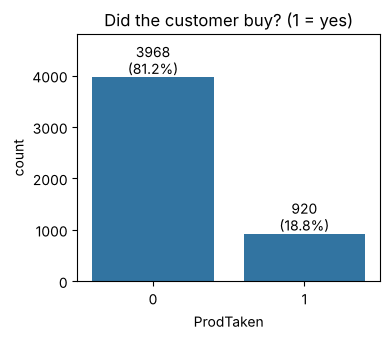

In [9]:
# --- 1) Target balance ---
fig, ax = plt.subplots(figsize=(4, 3.5))
sns.countplot(x="ProdTaken", data=df, ax=ax)
for p in ax.patches:
    ax.annotate(f"{p.get_height():.0f}\n({p.get_height() / len(df) * 100:.1f}%)",
                (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
ax.set_title("Did the customer buy? (1 = yes)")
ax.set_ylim(0, 4800)
plt.tight_layout()
plt.show()


**Inference (how many buy)**
- Only **920 of 4,888 customers (18.8%) bought**. The other 81.2% said no.
- This is an **imbalanced** problem: a model that says 'no' to everyone would be right 81% of the time but would find **zero** buyers. Accuracy cannot be our main score.

> **In simple words:** if 1 in 5 kids likes broccoli, guessing 'nobody likes it' is mostly right but useless for finding the broccoli fans.

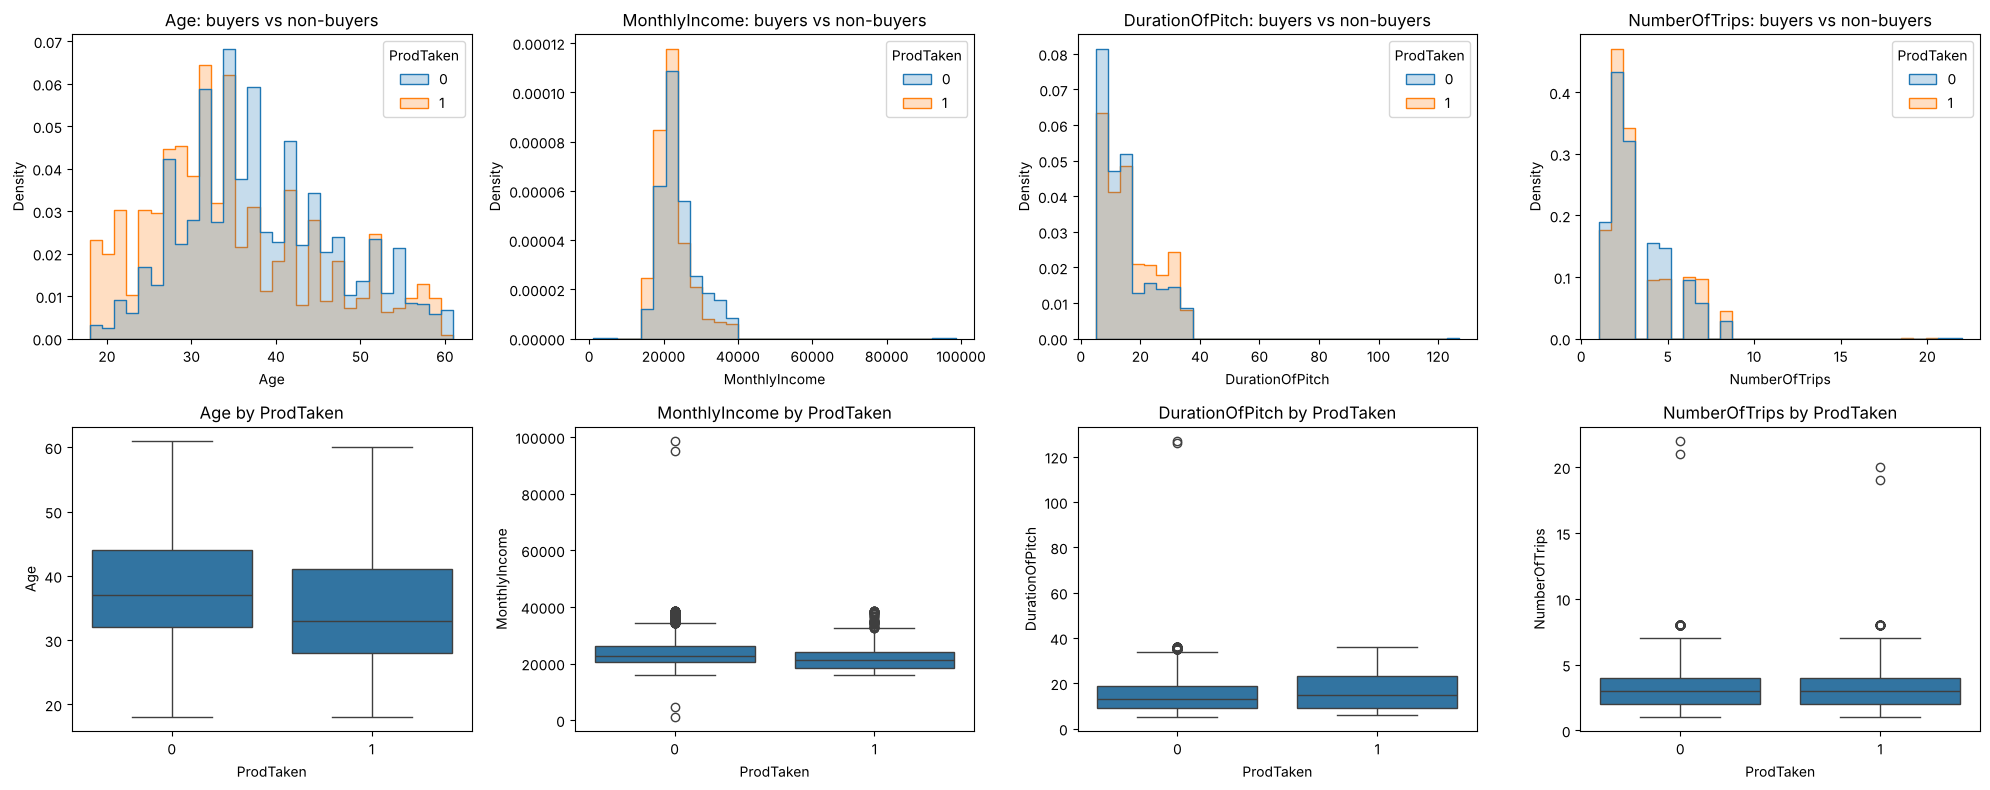

In [10]:
cont = ["Age", "MonthlyIncome", "DurationOfPitch", "NumberOfTrips"]
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for j, c in enumerate(cont):
    sns.histplot(data=df, x=c, hue="ProdTaken", stat="density",
                 common_norm=False, element="step", bins=30, ax=axes[0, j])
    axes[0, j].set_title(f"{c}: buyers vs non-buyers")
    sns.boxplot(data=df, x="ProdTaken", y=c, ax=axes[1, j])
    axes[1, j].set_title(f"{c} by ProdTaken")
plt.tight_layout()
plt.show()


In [11]:
print("\n=== AVERAGES: NON-BUYERS (0) vs BUYERS (1) ===")
num_all = df.select_dtypes(include="number").columns.drop("ProdTaken")
print(df.groupby("ProdTaken")[num_all].mean().T.round(2))

# --- 4) Outlier counts (IQR rule) ---
print("\n=== OUTLIERS (IQR rule) ===")
for c in cont:
    q1, q3 = df[c].quantile([.25, .75]); i = q3 - q1
    n = ((df[c] < q1 - 1.5 * i) | (df[c] > q3 + 1.5 * i)).sum()
    print(f"{c:18s} {n:4d} ({n / len(df) * 100:.1f}%)")


=== AVERAGES: NON-BUYERS (0) vs BUYERS (1) ===
ProdTaken                        0         1
Age                          38.28     34.77
CityTier                      1.62      1.82
DurationOfPitch              15.17     16.87
NumberOfPersonVisiting        2.90      2.92
NumberOfFollowups             3.65      3.94
PreferredPropertyStar         3.54      3.75
NumberOfTrips                 3.22      3.31
Passport                      0.23      0.54
PitchSatisfactionScore        3.04      3.22
OwnCar                        0.62      0.61
NumberOfChildrenVisiting      1.18      1.20
MonthlyIncome             23960.96  22172.83

=== OUTLIERS (IQR rule) ===
Age                   0 (0.0%)
MonthlyIncome       345 (7.1%)
DurationOfPitch       2 (0.0%)
NumberOfTrips       109 (2.2%)


**Inference (average buyer vs average non-buyer)**
- Buyers are **younger** (34.8 vs 38.3 years) and have a **passport far more often** (54% vs 23%).
- Buyers received a few more follow-up calls (3.94 vs 3.65) and prefer slightly higher star hotels (3.75 vs 3.54).
- `MonthlyIncome` is a little lower for buyers (22,173 vs 23,961). Income alone is **not** a strong signal.
- A few income values are very large (7.1% outliers). We will **cap** them so a handful of rich customers do not confuse the model.

> **In simple words:** buyers are a bit younger, travel-ready (passport), and were called back more often.

In [12]:
from scipy.stats import chi2_contingency

overall = df["ProdTaken"].mean()

# Text columns plus the small whole-number columns
cols = ["Designation", "MaritalStatus", "Occupation", "CityTier", "Passport",
        "Gender", "TypeofContact", "PreferredPropertyStar",
        "PitchSatisfactionScore", "NumberOfFollowups",
        "NumberOfPersonVisiting", "NumberOfChildrenVisiting", "OwnCar"]

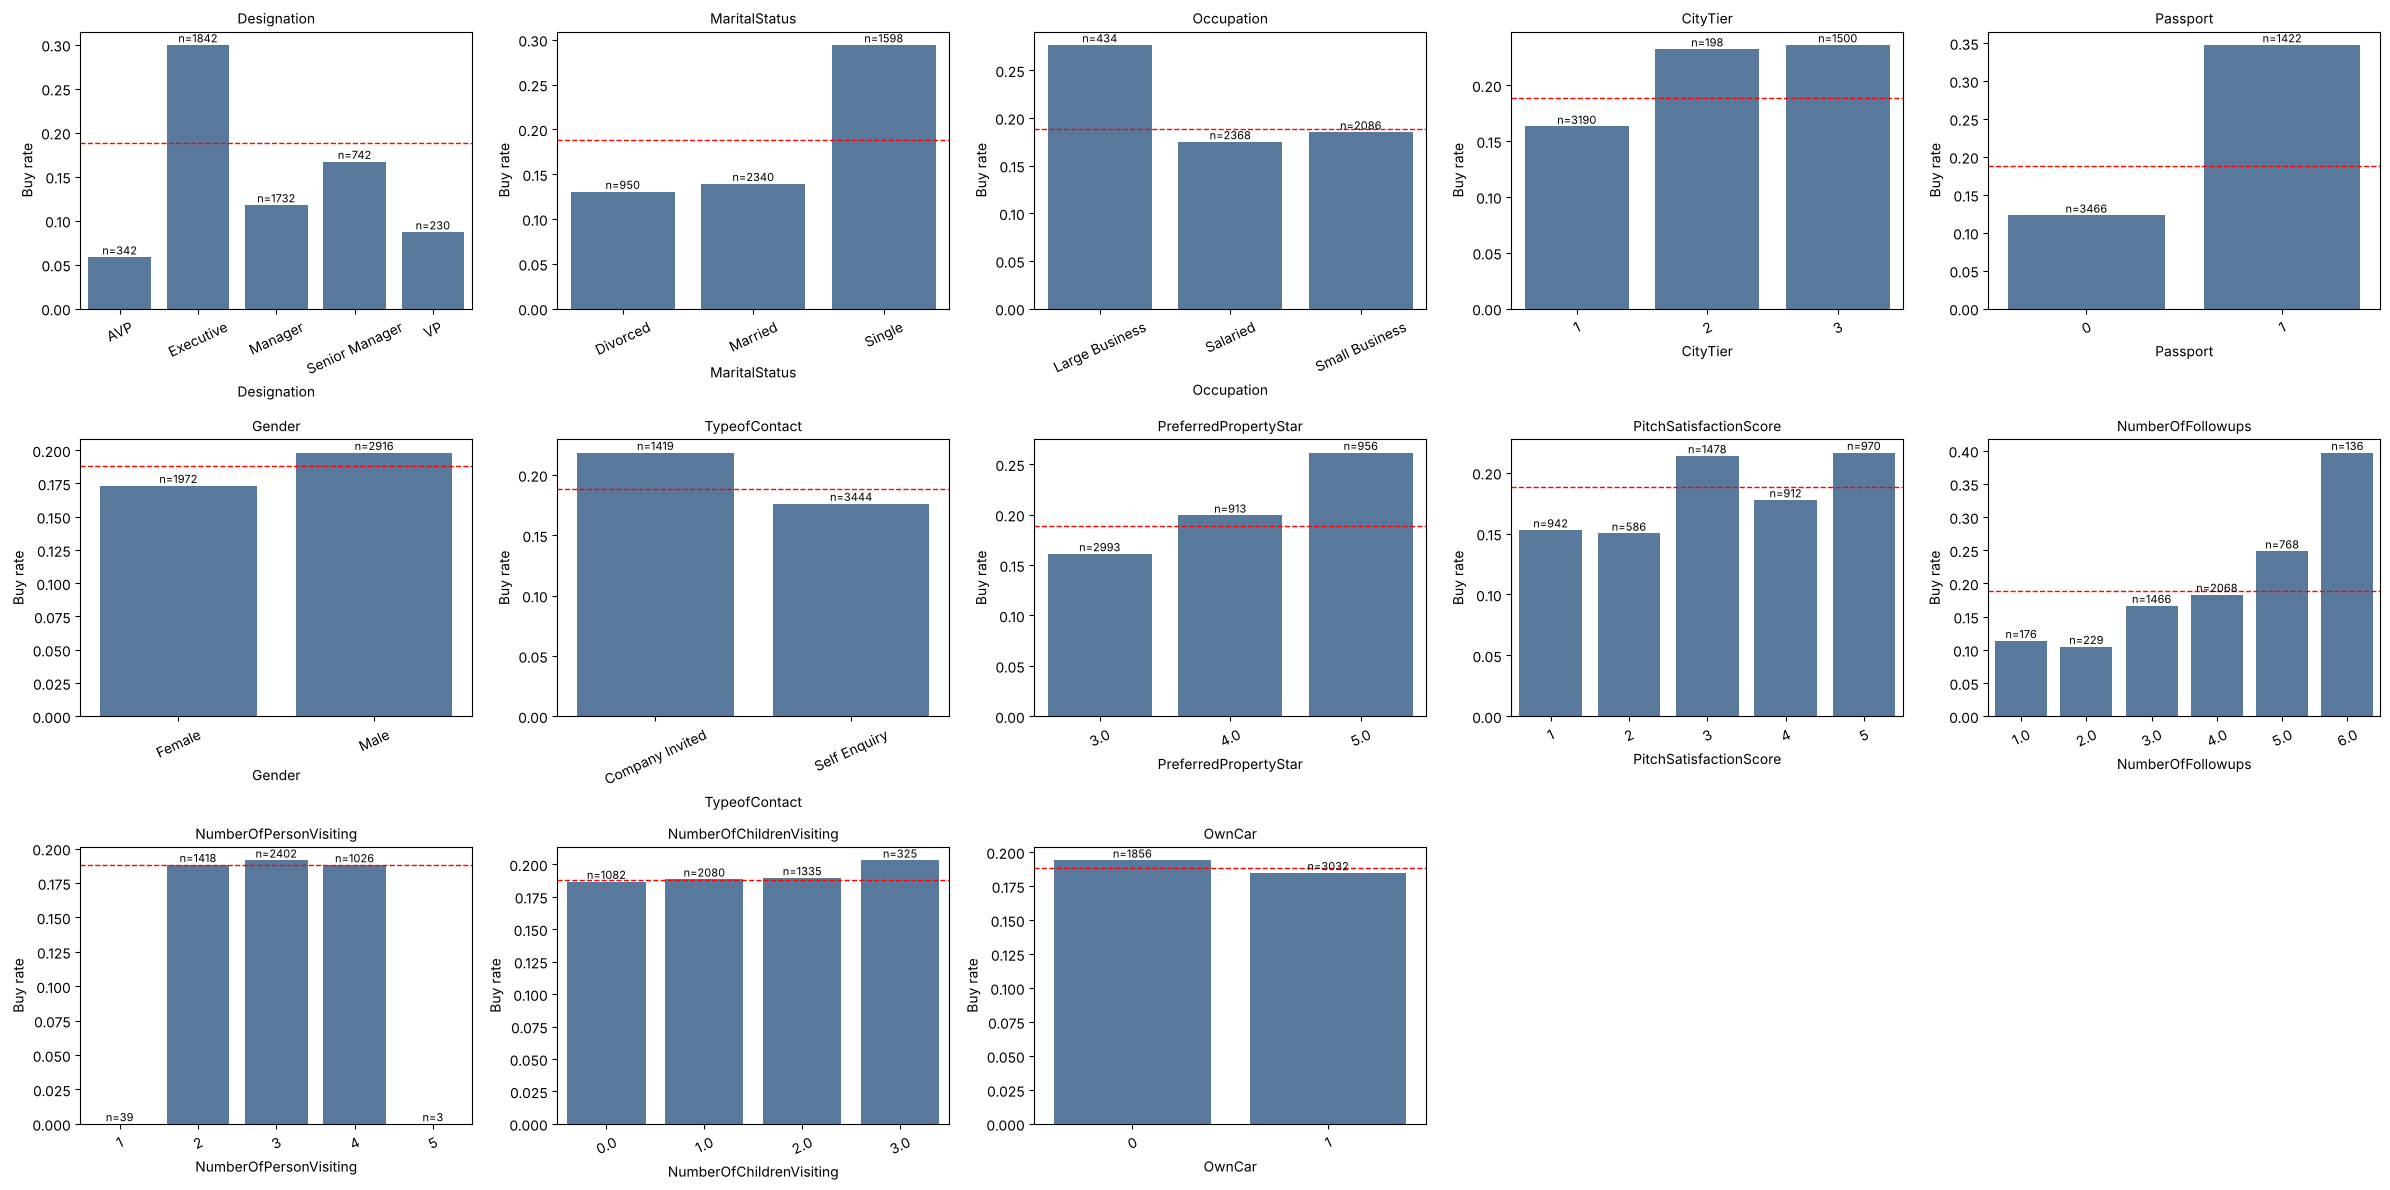

=== BUY RATE GAP BY FEATURE (overall rate = 0.188) ===
                 feature  highest_rate  lowest_rate   gap  chi2_p
       NumberOfFollowups         0.397        0.105 0.292 1.4e-15
             Designation         0.300        0.058 0.241 2.4e-55
                Passport         0.347        0.123 0.224 5.5e-74
  NumberOfPersonVisiting         0.192        0.000 0.192   0.042
           MaritalStatus         0.294        0.131 0.164 1.2e-38
              Occupation         0.276        0.175 0.102 3.6e-06
   PreferredPropertyStar         0.262        0.161 0.100 2.5e-11
                CityTier         0.236        0.163 0.073 5.1e-09
  PitchSatisfactionScore         0.216        0.150 0.066 4.3e-05
           TypeofContact         0.218        0.176 0.042 0.00072
                  Gender         0.198        0.173 0.025   0.033
NumberOfChildrenVisiting         0.203        0.187 0.016    0.93
                  OwnCar         0.194        0.185 0.009    0.44


In [13]:
fig, axes = plt.subplots(3, 5, figsize=(24, 12))
rows = []
for ax, c in zip(axes.ravel(), cols):
    g = df.groupby(c)["ProdTaken"].agg(["mean", "count"]).reset_index()
    sns.barplot(data=g, x=c, y="mean", ax=ax, color="#4C78A8")
    ax.axhline(overall, color="red", ls="--", lw=1)
    for i, r in g.iterrows():                      # show group size (n) on bars
        ax.text(i, r["mean"], f"n={int(r['count'])}", ha="center",
                va="bottom", fontsize=8)
    ax.set_title(c, fontsize=10)
    ax.set_ylabel("Buy rate")
    ax.tick_params(axis="x", rotation=25)
    # chi-square test of association with ProdTaken
    p = chi2_contingency(pd.crosstab(df[c], df["ProdTaken"]))[1]
    hi, lo = float(g["mean"].max()), float(g["mean"].min())
    rows.append({"feature": c, "highest_rate": round(hi, 3),
                 "lowest_rate": round(lo, 3),
                 "gap": round(hi - lo, 3),
                 "chi2_p": p})
for ax in axes.ravel()[len(cols):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

summary = pd.DataFrame(rows).sort_values("gap", ascending=False)
summary["chi2_p"] = summary["chi2_p"].apply(lambda v: f"{v:.2g}")
print(f"=== BUY RATE GAP BY FEATURE (overall rate = {overall:.3f}) ===")
print(summary.to_string(index=False))

**Inference (which facts separate buyers best)**
- The biggest gaps in buy rate: **follow-ups** (39.7% for the best group vs 10.5%), **job level** (30.0% vs 5.8%), **passport** (34.7% vs 12.3%) and **marital status** (29.4% vs 13.1%).
- Also useful: Large Business owners (27.6%), customers who prefer 5-star hotels (26.2%) and customers from Tier 3 cities (23.6%).
- `OwnCar` and `NumberOfChildrenVisiting` hardly change the buy rate, so they are weak clues.

> **In simple words:** the 'who buys' story is mostly about job level, passport, being single and how many times we followed up.

=== SEGMENT BUY RATES (overall = 0.188) ===
                                     segment  customers  buyers  buy_rate  lift  reliable
                               All customers       4888     920     0.188  1.00      True
                                   Executive       1842     552     0.300  1.59      True
                        Executive + Passport        568     322     0.567  3.01      True
               Executive + Passport + Tier 3         82      64     0.780  4.15      True
               Executive + Passport + Single        214     158     0.738  3.92      True
      Executive + Passport + Tier 3 + Single         52      44     0.846  4.50      True
Passport + Tier 3 + Single (any designation)        182     124     0.681  3.62      True
                              Large Business        434     120     0.276  1.47      True
                        Income 15,000-25,000       3295     711     0.216  1.15      True
                                   Age 18-30       1115 

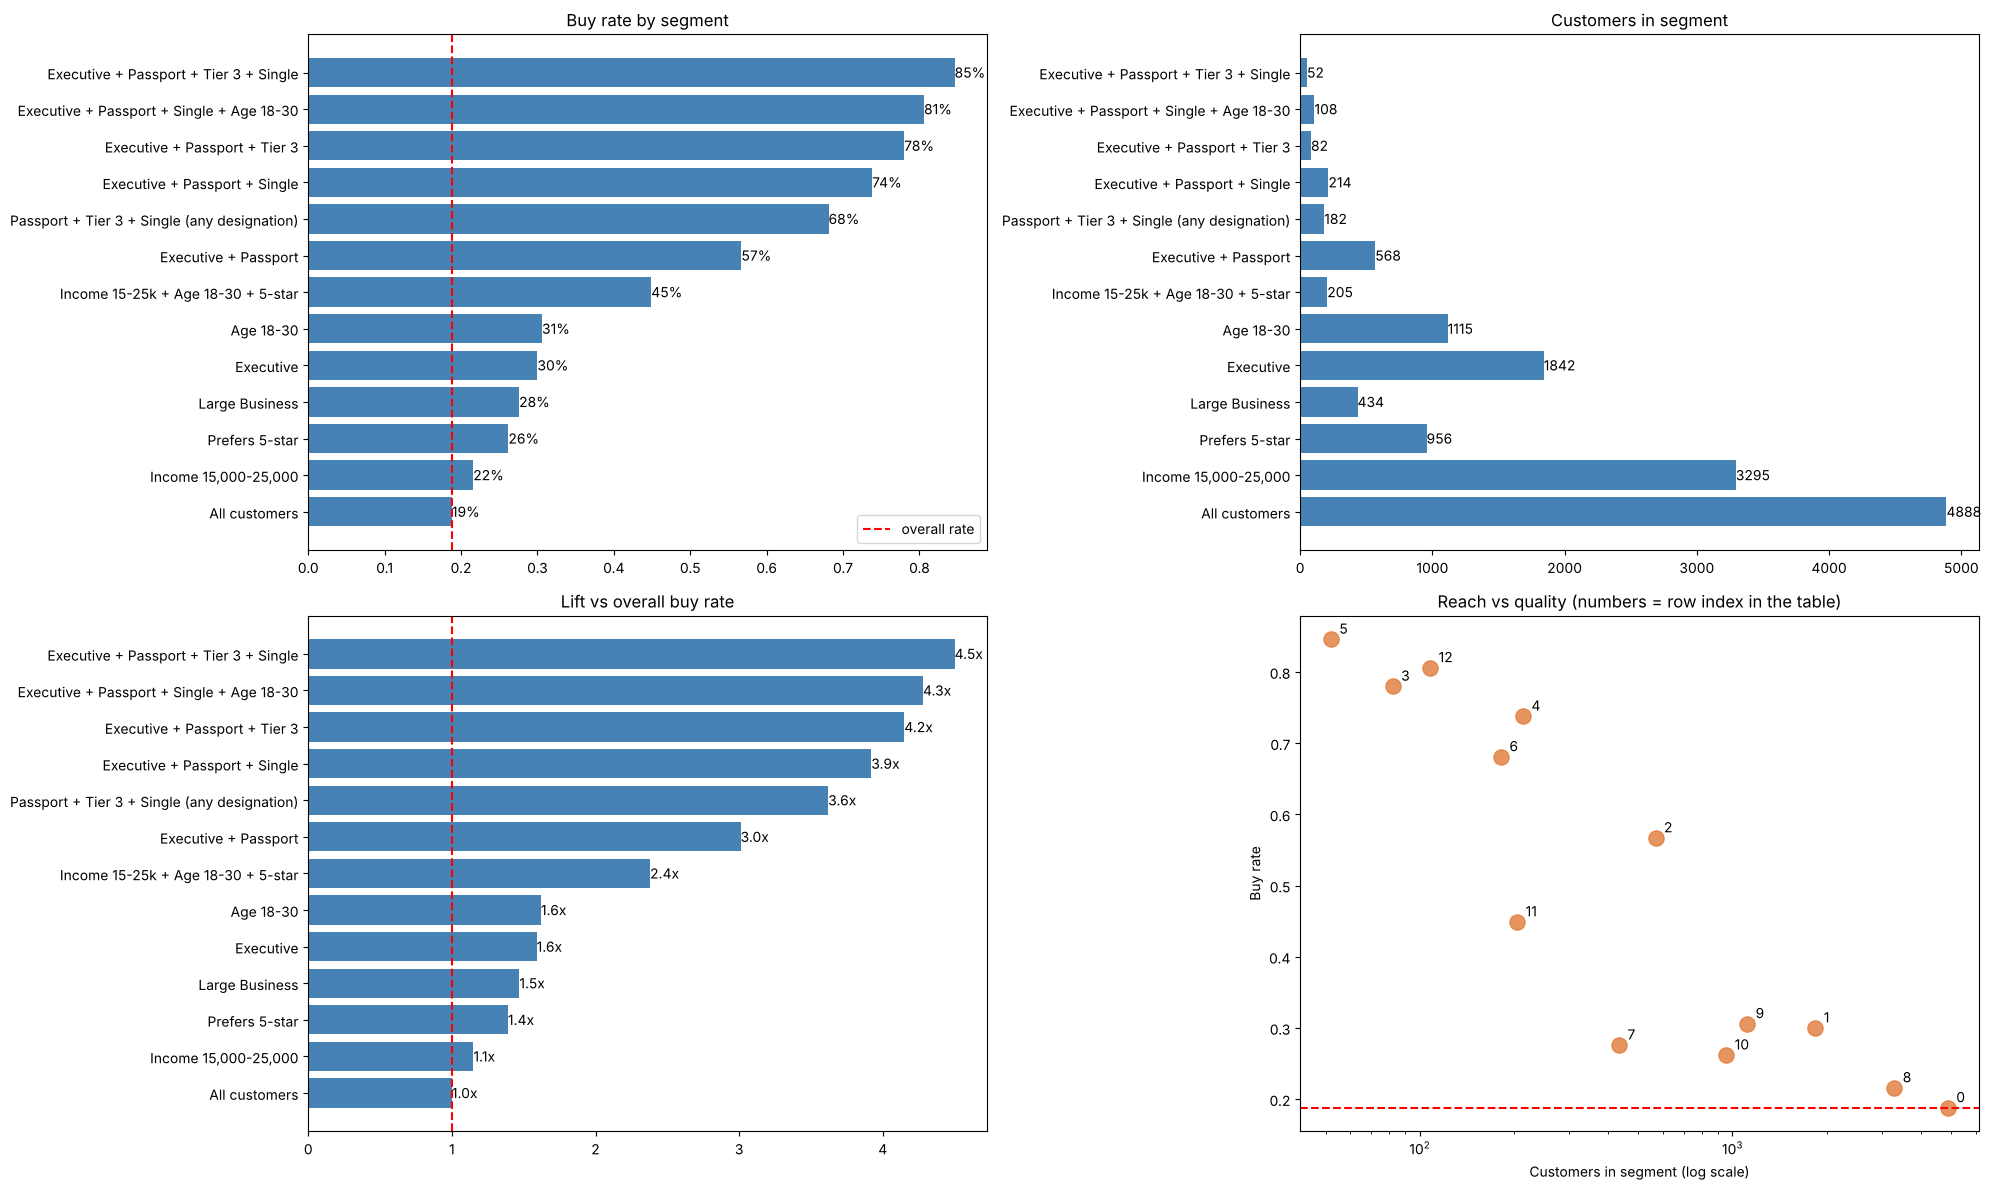

In [14]:
def seg(mask, name):
    """Return size, buyers, buy rate and lift for one customer segment."""
    sub = df[mask]
    n = len(sub)
    rate = sub["ProdTaken"].mean() if n else np.nan
    return {
        "segment": name,
        "customers": n,
        "buyers": int(sub["ProdTaken"].sum()),
        "buy_rate": round(rate, 3),
        "lift": round(rate / overall, 2),
        "reliable": n >= 30,
    }


# Segment definitions (NaN rows are excluded from Age/Income masks)
exe = df["Designation"] == "Executive"
pas = df["Passport"] == 1
t3 = df["CityTier"] == 3
sgl = df["MaritalStatus"] == "Single"
lb = df["Occupation"] == "Large Business"
inc = df["MonthlyIncome"].between(15000, 25000)
age = df["Age"].between(18, 30)
star5 = df["PreferredPropertyStar"] == 5

segments = [
    seg(df.index == df.index, "All customers"),
    seg(exe, "Executive"),
    seg(exe & pas, "Executive + Passport"),
    seg(exe & pas & t3, "Executive + Passport + Tier 3"),
    seg(exe & pas & sgl, "Executive + Passport + Single"),
    seg(exe & pas & t3 & sgl, "Executive + Passport + Tier 3 + Single"),
    seg(pas & t3 & sgl, "Passport + Tier 3 + Single (any designation)"),
    seg(lb, "Large Business"),
    seg(inc, "Income 15,000-25,000"),
    seg(age, "Age 18-30"),
    seg(star5, "Prefers 5-star"),
    seg(inc & age & star5, "Income 15-25k + Age 18-30 + 5-star"),
    seg(exe & pas & sgl & age, "Executive + Passport + Single + Age 18-30"),
]
seg_df = pd.DataFrame(segments)
print("=== SEGMENT BUY RATES (overall = %.3f) ===" % overall)
print(seg_df.to_string(index=False))

# --- Plots: sorted by buy rate so the best segments sit at the top ---
plot_df = seg_df.sort_values("buy_rate").reset_index(drop=True)
bar_colors = ["steelblue" if ok else "lightgrey" for ok in plot_df["reliable"]]

fig, axes = plt.subplots(2, 2, figsize=(20, 12))

# 1. Buy rate per segment (grey = fewer than 30 customers, unreliable)
b = axes[0, 0].barh(plot_df["segment"], plot_df["buy_rate"], color=bar_colors)
axes[0, 0].axvline(overall, color="red", ls="--", label="overall rate")
axes[0, 0].bar_label(b, labels=[f"{r:.0%}" for r in plot_df["buy_rate"]])
axes[0, 0].set_title("Buy rate by segment")
axes[0, 0].legend()

# 2. Segment size
b = axes[0, 1].barh(plot_df["segment"], plot_df["customers"], color=bar_colors)
axes[0, 1].bar_label(b)
axes[0, 1].set_title("Customers in segment")

# 3. Lift over the overall rate (1.0 = no better than average)
b = axes[1, 0].barh(plot_df["segment"], plot_df["lift"], color=bar_colors)
axes[1, 0].axvline(1, color="red", ls="--")
axes[1, 0].bar_label(b, labels=[f"{v:.1f}x" for v in plot_df["lift"]])
axes[1, 0].set_title("Lift vs overall buy rate")

# 4. Trade-off: reach (size) vs quality (buy rate), numbered by table order
axes[1, 1].scatter(seg_df["customers"], seg_df["buy_rate"],
                   s=120, c="#e07b39", alpha=0.8)
for i, row in seg_df.iterrows():
    axes[1, 1].annotate(str(i), (row["customers"], row["buy_rate"]),
                        textcoords="offset points", xytext=(6, 4))
axes[1, 1].axhline(overall, color="red", ls="--")
axes[1, 1].set_xscale("log")
axes[1, 1].set_xlabel("Customers in segment (log scale)")
axes[1, 1].set_ylabel("Buy rate")
axes[1, 1].set_title("Reach vs quality (numbers = row index in the table)")

plt.tight_layout()
plt.show()

**Inference (customer groups)**
- **Executives** buy 30.0% of the time (1.6x the average).
- Executives **with a passport** buy **56.7%** (568 customers) and adding **Single** lifts it to **73.8%** (214 customers).
- The very best mix (Executive + Passport + Tier 3 + Single) buys 84.6%, but it has only **52 customers**, so it is a small pocket, not a plan by itself.

> **In simple words:** a few simple clues together make a very strong buyer profile, but we need a model to weigh all clues at once.

---
## Part 5: Split the data and prepare it for the model
We hide 20% of customers as the final exam, then fill blanks, cap extremes, scale numbers and turn words into numbers using the practice data only.

In [15]:
import pandas as pd
from sklearn.model_selection import train_test_split

# 1. Load the cleaned file and verify it is the right version
assert df.shape == (4888, 18), f"Unexpected shape: {df.shape}"
assert "Designation" in df.columns and "ProductPitched" not in df.columns
assert "Unmarried" not in df["MaritalStatus"].unique()
assert "Free Lancer" not in df["Occupation"].unique()

# 2. Separate features (X) and target (y)
X = df.drop(columns="ProdTaken")
y = df["ProdTaken"]

# 3. Stratified 80/20 split with a fixed seed for reproducibility
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 4. Verify shapes and class ratios
print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("\nBuy rate overall:", round(y.mean() * 100, 2), "%")
print("Buy rate train:  ", round(y_train.mean() * 100, 2), "%")
print("Buy rate test:   ", round(y_test.mean() * 100, 2), "%")
print("\nTrain class counts:", y_train.value_counts().to_dict())
print("Test class counts: ", y_test.value_counts().to_dict())

# 5. Column types, to design the preprocessing in the next step
print("\nCategorical:", X_train.select_dtypes(include="object").columns.tolist())
print("Numeric:    ", X_train.select_dtypes(exclude="object").columns.tolist())

# 6. Remaining nulls in the training set
nulls = X_train.isnull().sum()
print("\nTrain nulls:\n", nulls[nulls > 0])

X_train: (3910, 17) | X_test: (978, 17)

Buy rate overall: 18.82 %
Buy rate train:   18.82 %
Buy rate test:    18.81 %

Train class counts: {0: 3174, 1: 736}
Test class counts:  {0: 794, 1: 184}

Categorical: ['TypeofContact', 'Occupation', 'Gender', 'MaritalStatus', 'Designation']
Numeric:     ['Age', 'CityTier', 'DurationOfPitch', 'NumberOfPersonVisiting', 'NumberOfFollowups', 'PreferredPropertyStar', 'NumberOfTrips', 'Passport', 'PitchSatisfactionScore', 'OwnCar', 'NumberOfChildrenVisiting', 'MonthlyIncome']

Train nulls:
 Age                         183
TypeofContact                17
DurationOfPitch             194
NumberOfFollowups            39
PreferredPropertyStar        19
NumberOfTrips               107
NumberOfChildrenVisiting     53
MonthlyIncome               183
dtype: int64


**Inference (train / test split)**
- **3,910 customers to train** and **978 to test**. Both have the same buy rate (18.8%), so the exam is fair.
- The test group stays untouched until the model is chosen.

> **In simple words:** we keep 1 exam paper locked in a drawer until we are ready to be graded.

In [16]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# 1. Work on copies so the originals stay untouched
X_train = X_train.copy()
X_test = X_test.copy()

# 2. Cap extreme values using limits learned from TRAIN only
for col in ["DurationOfPitch", "NumberOfTrips", "MonthlyIncome"]:
    low, high = X_train[col].quantile([0.01, 0.99])
    X_train[col] = X_train[col].clip(low, high)
    X_test[col] = X_test[col].clip(low, high)  # same limits for test
    print(f"{col}: capped to [{low:.0f}, {high:.0f}]")

# 3. Column groups
num_cols = ["Age", "MonthlyIncome", "DurationOfPitch", "NumberOfTrips",
            "NumberOfPersonVisiting", "NumberOfFollowups",
            "PreferredPropertyStar", "PitchSatisfactionScore",
            "NumberOfChildrenVisiting"]
cat_cols = ["CityTier", "TypeofContact", "Occupation", "Gender",
            "MaritalStatus", "Designation"]
bin_cols = ["Passport", "OwnCar"]  # already 0/1

# 4. Numeric: fill with median, then scale
num_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])

# 5. Categorical: fill with most frequent, then one-hot encode
cat_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

# 6. Combine
preprocessor = ColumnTransformer([
    ("num", num_pipe, num_cols),
    ("cat", cat_pipe, cat_cols),
    ("bin", "passthrough", bin_cols),
]).set_output(transform="pandas")

# 7. Fit on TRAIN only, then transform both
Xtr = preprocessor.fit_transform(X_train)
Xte = preprocessor.transform(X_test)

# 8. Checks
print("\nTrain shape:", Xtr.shape, "| Test shape:", Xte.shape)
print("Nulls train:", int(Xtr.isna().sum().sum()), "| test:", int(Xte.isna().sum().sum()))
print("\nScaled numeric columns (train mean ~0, std ~1):")
print(Xtr[[f"num__{c}" for c in num_cols]].agg(["mean", "std"]).T.round(2))
print("\nFeature names:\n", list(Xtr.columns))

DurationOfPitch: capped to [6, 35]
NumberOfTrips: capped to [1, 8]
MonthlyIncome: capped to [16885, 38084]

Train shape: (3910, 29) | Test shape: (978, 29)
Nulls train: 0 | test: 0

Scaled numeric columns (train mean ~0, std ~1):
                               mean  std
num__Age                       -0.0  1.0
num__MonthlyIncome              0.0  1.0
num__DurationOfPitch            0.0  1.0
num__NumberOfTrips              0.0  1.0
num__NumberOfPersonVisiting    -0.0  1.0
num__NumberOfFollowups         -0.0  1.0
num__PreferredPropertyStar     -0.0  1.0
num__PitchSatisfactionScore    -0.0  1.0
num__NumberOfChildrenVisiting   0.0  1.0

Feature names:
 ['num__Age', 'num__MonthlyIncome', 'num__DurationOfPitch', 'num__NumberOfTrips', 'num__NumberOfPersonVisiting', 'num__NumberOfFollowups', 'num__PreferredPropertyStar', 'num__PitchSatisfactionScore', 'num__NumberOfChildrenVisiting', 'cat__CityTier_1', 'cat__CityTier_2', 'cat__CityTier_3', 'cat__TypeofContact_Company Invited', 'cat__TypeofCont

**Inference (preparation)**
- Extreme values were capped (pitch time 6-35 minutes, trips 1-8, income 16,885-38,084) using **training data limits only**.
- After filling blanks and turning words into 0/1 columns, we have **29 model-ready columns** and no blanks left.

> **In simple words:** we tidied the data the same way for every customer so the model compares like with like.

---
## Part 6: First model and the imbalance fix
A simple model (logistic regression) shows what 'good' looks like. Then we tell it that finding buyers matters more.

In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score)

# 1. Two models: identical except for class weighting
models = {
    "Baseline": LogisticRegression(max_iter=1000, random_state=42),
    "Weighted": LogisticRegression(max_iter=1000, random_state=42,
                                   class_weight="balanced"),
}

# 2. Train each, then score on both train and test at the default 0.5 threshold
rows = []
for name, model in models.items():
    model.fit(Xtr, y_train)
    for split, X_, y_ in [("train", Xtr, y_train), ("test", Xte, y_test)]:
        proba = model.predict_proba(X_)[:, 1]
        pred = (proba >= 0.5).astype(int)
        rows.append({
            "model": name,
            "split": split,
            "accuracy": accuracy_score(y_, pred),
            "precision": precision_score(y_, pred, zero_division=0),
            "recall": recall_score(y_, pred),
            "f1": f1_score(y_, pred),
            "roc_auc": roc_auc_score(y_, proba),
            "flagged_as_buyer": int(pred.sum()),
        })

print(pd.DataFrame(rows).round(3).to_string(index=False))

# 3. Accuracy trap: what a model that always says "No" would score on test
print("\nAlways-predict-No accuracy (test):", round(1 - y_test.mean(), 3))
print("Actual buyers in test:", int(y_test.sum()))

   model split  accuracy  precision  recall    f1  roc_auc  flagged_as_buyer
Baseline train     0.851      0.710   0.349 0.468    0.825               362
Baseline  test     0.830      0.625   0.245 0.352    0.767                72
Weighted train     0.755      0.417   0.760 0.539    0.826              1339
Weighted  test     0.724      0.373   0.685 0.483    0.767               338

Always-predict-No accuracy (test): 0.812
Actual buyers in test: 184


**Inference (baseline vs weighted)**
- The plain model has **83.0% accuracy** but finds only about **1 in 4 buyers** (recall 24.5%). A model that always says 'no' scores 81.2%, so 83.0% is not impressive.
- The **weighted** model treats a missed buyer as more costly. Accuracy drops to 72.4%, but it finds **68.5% of buyers**.
- Both have the same ranking skill (AUC 0.767). Weighting changes **who gets flagged**, not how well customers are ranked.

> **In simple words:** we trade a few wrong calls for finding many more real buyers, which is what the sales team wants.

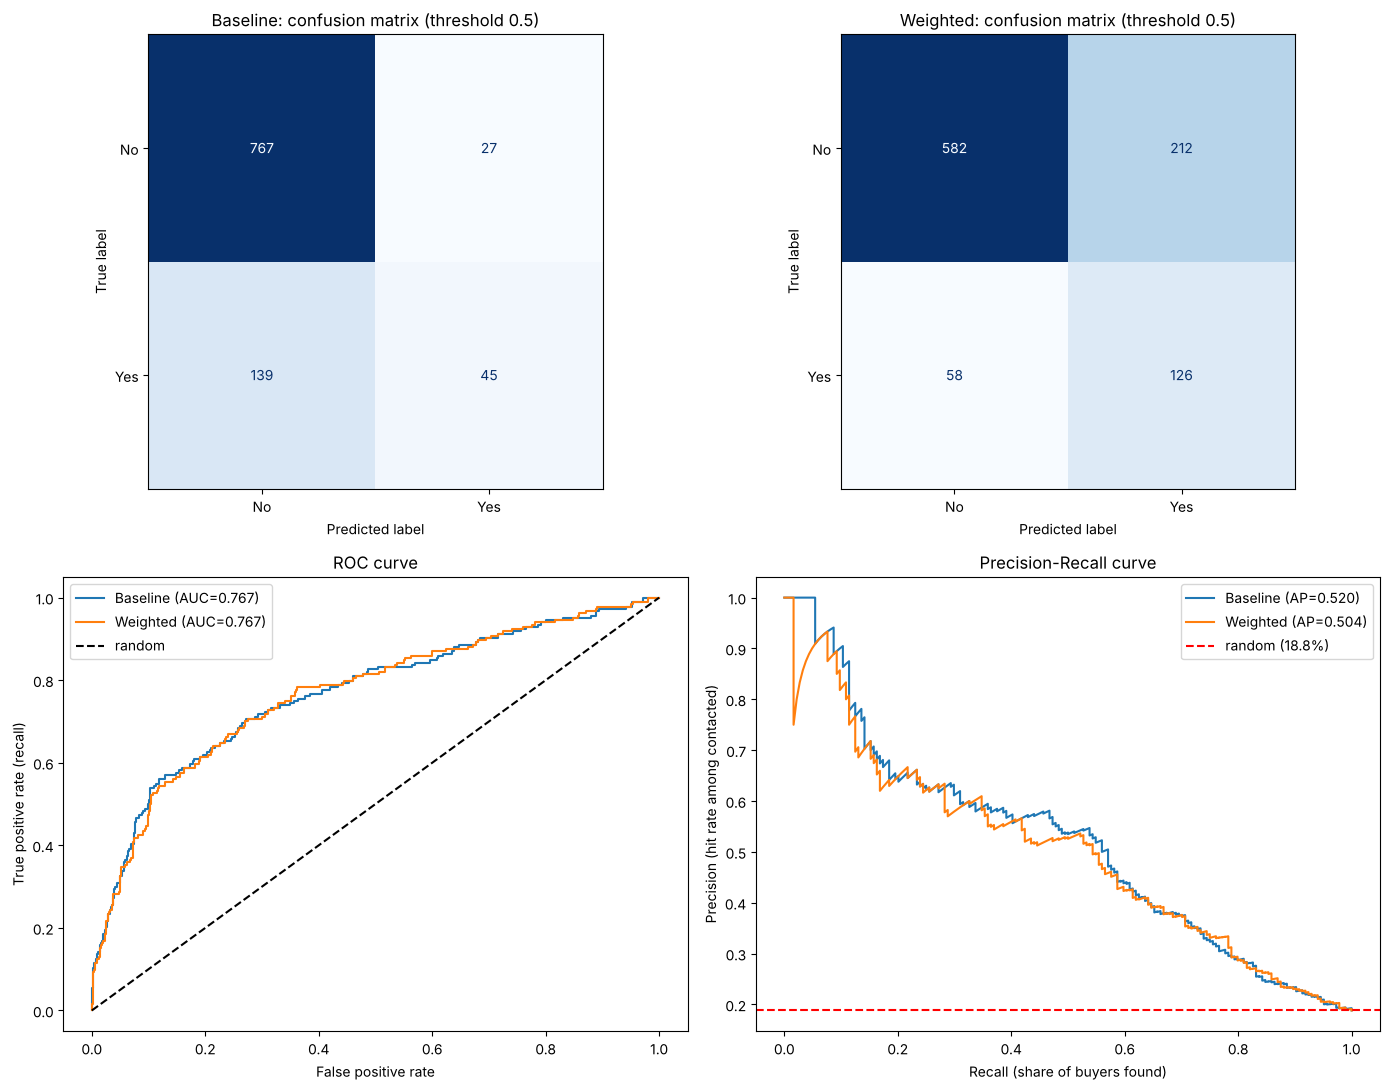

In [18]:
from sklearn.metrics import (ConfusionMatrixDisplay, roc_curve,
                             precision_recall_curve, average_precision_score)

# 1. Test-set probabilities for both models
proba = {name: m.predict_proba(Xte)[:, 1] for name, m in models.items()}

fig, axes = plt.subplots(2, 2, figsize=(14, 11))

# 2. Confusion matrices at the default 0.5 threshold
for ax, (name, p) in zip(axes[0], proba.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, (p >= 0.5).astype(int), display_labels=["No", "Yes"],
        cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(f"{name}: confusion matrix (threshold 0.5)")

# 3. ROC curves
for name, p in proba.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[1, 0].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, p):.3f})")
axes[1, 0].plot([0, 1], [0, 1], "k--", label="random")
axes[1, 0].set_xlabel("False positive rate")
axes[1, 0].set_ylabel("True positive rate (recall)")
axes[1, 0].set_title("ROC curve")
axes[1, 0].legend()

# 4. Precision-Recall curves (more informative with an 18.8% positive rate)
for name, p in proba.items():
    prec, rec, _ = precision_recall_curve(y_test, p)
    ap = average_precision_score(y_test, p)
    axes[1, 1].plot(rec, prec, label=f"{name} (AP={ap:.3f})")
axes[1, 1].axhline(y_test.mean(), color="red", ls="--", label="random (18.8%)")
axes[1, 1].set_xlabel("Recall (share of buyers found)")
axes[1, 1].set_ylabel("Precision (hit rate among contacted)")
axes[1, 1].set_title("Precision-Recall curve")
axes[1, 1].legend()

plt.tight_layout()
plt.show()

**Inference (charts)**
- The confusion matrices show the same story: the weighted model finds many more buyers but also flags more non-buyers.
- Both ROC and precision-recall lines sit above the 'random' line, so even the simple model has some skill. We will beat it later.

> **In simple words:** the higher and further left the line, the better the model.

---
## Part 7: Explain the factors: what raises or lowers the chance to buy?
A logistic model is easy to read. We turn its numbers into **odds ratios**: 2.0 means 'twice the odds', 0.5 means 'half the odds'.

Weighted logistic regression: class_weight = balanced

=== TOP 15 FEATURES BY |COEFFICIENT| ===
                        feature   coef  odds_ratio
                  bin__Passport  1.553        4.73
           cat__Designation_AVP -1.226        0.29
     cat__Designation_Executive  1.212        3.36
                cat__CityTier_1 -0.708        0.49
      cat__MaritalStatus_Single  0.535        1.71
    cat__MaritalStatus_Divorced -0.448        0.64
                cat__CityTier_3  0.394        1.48
     cat__MaritalStatus_Married -0.379        0.68
         num__NumberOfFollowups  0.371        1.45
cat__Designation_Senior Manager  0.356        1.43
       cat__Designation_Manager -0.351        0.70
     num__PreferredPropertyStar  0.340        1.40
 cat__Occupation_Large Business  0.324        1.38
       cat__Occupation_Salaried -0.318        0.73
           num__DurationOfPitch  0.306        1.36


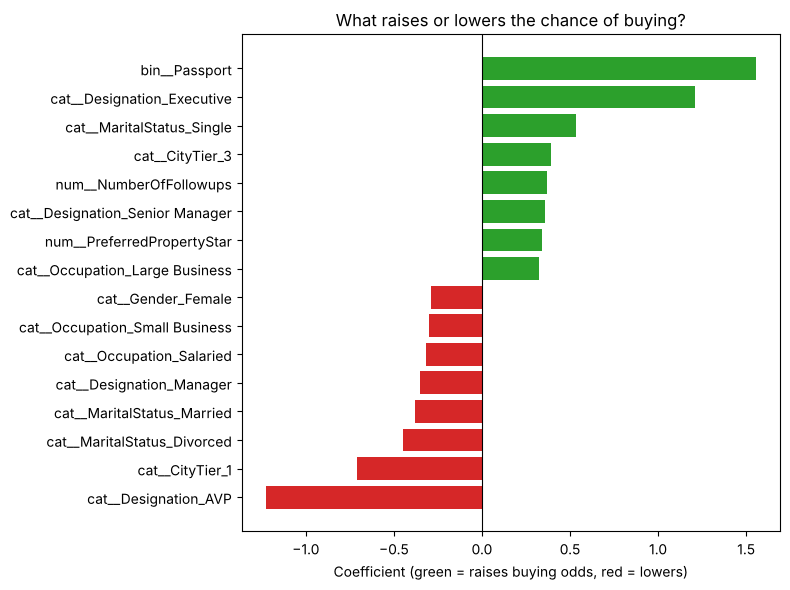

In [19]:
prep = preprocessor
clf = models["Weighted"]
X_tr, y_tr = X_train, y_train

# Which model is this? (weighted = class_weight is 'balanced' or a dict)
print("Weighted logistic regression: class_weight =", clf.class_weight)

names = prep.get_feature_names_out()
assert len(names) == clf.coef_.shape[1], "preprocessor and model don't match"

# 1) Coefficients and odds ratios from the sklearn model
coefs = pd.DataFrame({"feature": names, "coef": clf.coef_[0]})
coefs["odds_ratio"] = np.exp(coefs["coef"]).round(2)
coefs["abs_coef"] = coefs["coef"].abs()
coefs = coefs.sort_values("abs_coef", ascending=False)
print("\n=== TOP 15 FEATURES BY |COEFFICIENT| ===")
print(coefs.head(15)[["feature", "coef", "odds_ratio"]].round(3).to_string(index=False))

# 2) Chart: strongest positive and negative effects
top = pd.concat([coefs[coefs["coef"] > 0].head(8),
                 coefs[coefs["coef"] < 0].head(8)]).sort_values("coef")
plt.figure(figsize=(8, 6))
plt.barh(top["feature"], top["coef"],
         color=["#d62728" if c < 0 else "#2ca02c" for c in top["coef"]])
plt.axvline(0, color="k", lw=0.8)
plt.xlabel("Coefficient (green = raises buying odds, red = lowers)")
plt.title("What raises or lowers the chance of buying?")
plt.tight_layout()
plt.show()


In [20]:
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

cat_raw = ["Designation", "MaritalStatus", "Occupation", "CityTier",
           "Gender", "TypeofContact"]

Xp = prep.transform(X_train)
Xp = Xp.toarray() if hasattr(Xp, "toarray") else np.asarray(Xp)
Xp = pd.DataFrame(Xp, columns=names)

# Drop the most frequent level of each fully-expanded category (the baseline)
drop_cols = []
for c in cat_raw:
    cols = [n for n in names if n.startswith(f"cat__{c}_")]
    if c in X_train.columns and len(cols) >= 2 \
            and len(cols) == X_train[c].nunique(dropna=True):
        ref = X_train[c].value_counts().idxmax()
        if f"cat__{c}_{ref}" in names:
            drop_cols.append(f"cat__{c}_{ref}")
print("Baseline (reference) levels dropped:", drop_cols)

Xr = Xp.drop(columns=drop_cols)
Xr = Xr.loc[:, Xr.std() > 0]

# Refit the plain logistic regression
res = sm.Logit(np.asarray(y_train), sm.add_constant(Xr)).fit(disp=0, maxiter=300)
print("Converged:", res.mle_retvals["converged"])

ci = res.conf_int()
out = pd.DataFrame({"odds_ratio": np.exp(res.params),
                    "ci_low": np.exp(ci[0]), "ci_high": np.exp(ci[1]),
                    "p_value": res.pvalues}).drop("const").sort_values("p_value")
out["signif"] = np.where(out["p_value"] < 0.05, "yes", "no")
print("\n=== ALL FEATURES (baseline levels dropped) ===")
print(out.round(3).to_string())

# VIF: how much each feature overlaps with the others (> 5 is a warning)
vif = pd.Series([variance_inflation_factor(Xr.values, i)
                 for i in range(Xr.shape[1])], index=Xr.columns)
print("\n=== TOP 8 VIF ===")
print(vif.sort_values(ascending=False).head(8).round(2))

Baseline (reference) levels dropped: ['cat__Designation_Executive', 'cat__MaritalStatus_Married', 'cat__Occupation_Salaried', 'cat__CityTier_1', 'cat__Gender_Male', 'cat__TypeofContact_Self Enquiry']


Converged: True

=== ALL FEATURES (baseline levels dropped) ===
                                    odds_ratio  ci_low  ci_high  p_value signif
bin__Passport                            5.236   4.308    6.364    0.000    yes
cat__Designation_Manager                 0.189   0.144    0.247    0.000    yes
cat__CityTier_3                          3.135   2.510    3.917    0.000    yes
cat__MaritalStatus_Single                2.663   2.161    3.281    0.000    yes
num__PreferredPropertyStar               1.406   1.285    1.538    0.000    yes
num__NumberOfFollowups                   1.471   1.320    1.639    0.000    yes
cat__Designation_AVP                     0.079   0.037    0.169    0.000    yes
num__DurationOfPitch                     1.354   1.235    1.486    0.000    yes
cat__Designation_Senior Manager          0.310   0.211    0.454    0.000    yes
cat__Designation_VP                      0.183   0.077    0.436    0.000    yes
cat__CityTier_2                          2.174   1.420  

**Inference (what the model learned)**
- **Passport** is the strongest signal (odds ratio **5.2**): customers with a passport are about five times as likely to buy.
- **City Tier 3** (3.1) and **Single** customers (2.7) are much more likely to buy. **Executives** are the baseline job level; every higher level is much **less** likely (Manager 0.19, Senior Manager 0.31, VP 0.18, AVP 0.08).
- More **follow-ups** (1.47), a higher **preferred hotel star** (1.41) and a longer **pitch** (1.35) also help. Older customers are a little less likely (0.87 per age step).
- `OwnCar`, `NumberOfPersonVisiting` and `MonthlyIncome` are **not** statistically significant: they add no reliable information once the other facts are known.

> **In simple words:** the model says: young-ish, single, executive-level customers with a passport are the ones who say yes.

---
## Part 8: Before the call vs after the call
Some facts (pitch length, follow-ups, satisfaction) are only known **after** the sales call starts. To plan **who to call**, we need a model that uses only facts known **before** calling.

                model          CV_AUC  Test_AUC  Test_AP  buyers_in_top20%  buyers_in_top40%
Model A (pre-contact) 0.804 +/- 0.020     0.749    0.481             0.522             0.696
   Full (incl. pitch) 0.819 +/- 0.018     0.767    0.504             0.543             0.734


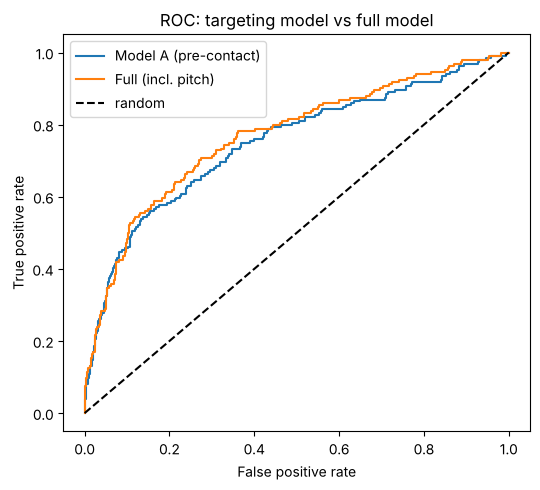

In [21]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve

# Features known only AFTER the sales call are removed for Model A
pitch_cols = ["DurationOfPitch", "NumberOfFollowups",
              "PitchSatisfactionScore", "TypeofContact"]
XA_train = X_train.drop(columns=pitch_cols)
XA_test = X_test.drop(columns=pitch_cols)

num_A = ["Age", "MonthlyIncome", "NumberOfTrips", "NumberOfPersonVisiting",
         "NumberOfChildrenVisiting", "PreferredPropertyStar"]
bin_A = ["Passport", "OwnCar"]
cat_A = ["Designation", "MaritalStatus", "Occupation", "CityTier", "Gender"]
assert set(num_A + bin_A + cat_A) == set(XA_train.columns), \
    set(XA_train.columns) ^ set(num_A + bin_A + cat_A)

prep_A = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                      ("sc", StandardScaler())]), num_A),
    ("bin", SimpleImputer(strategy="most_frequent"), bin_A),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("oh", OneHotEncoder(drop="first",
                                           handle_unknown="ignore"))]), cat_A),
])
pipe_A = Pipeline([("prep", prep_A),
                   ("clf", LogisticRegression(class_weight="balanced",
                                              max_iter=1000))])

# Full model rebuilt as a pipeline from YOUR objects (same settings)
pipe_F = Pipeline([("prep", clone(preprocessor)), ("clf", clone(models["Weighted"]))])

def top_share(y, p, frac):
    """Share of all buyers found in the top `frac` of customers by score."""
    k = int(len(y) * frac)
    return np.asarray(y)[np.argsort(-p)[:k]].sum() / np.sum(y)

cv = StratifiedKFold(5, shuffle=True, random_state=42)
rows, curves = [], {}
for name, pipe, Xtr, Xte in [("Model A (pre-contact)", pipe_A, XA_train, XA_test),
                             ("Full (incl. pitch)", pipe_F, X_train, X_test)]:
    cvs = cross_val_score(pipe, Xtr, y_train, cv=cv, scoring="roc_auc")
    pipe.fit(Xtr, y_train)
    p = pipe.predict_proba(Xte)[:, 1]
    curves[name] = roc_curve(y_test, p)
    rows.append({"model": name,
                 "CV_AUC": f"{cvs.mean():.3f} +/- {cvs.std():.3f}",
                 "Test_AUC": round(roc_auc_score(y_test, p), 3),
                 "Test_AP": round(average_precision_score(y_test, p), 3),
                 "buyers_in_top20%": round(top_share(y_test, p, .2), 3),
                 "buyers_in_top40%": round(top_share(y_test, p, .4), 3)})
print(pd.DataFrame(rows).to_string(index=False))

plt.figure(figsize=(5.5, 5))
for name, (fpr, tpr, _) in curves.items():
    plt.plot(fpr, tpr, label=name)
plt.plot([0, 1], [0, 1], "k--", label="random")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("ROC: targeting model vs full model")
plt.legend()
plt.tight_layout()
plt.show()

**Inference (pre-contact model)**
- The model that uses only before-the-call facts (Model A) scores AUC **0.749** on the test set; adding call details only lifts it to **0.767**.
- So most of the power comes from facts we already know. We keep **Model A (pre-contact)** because it lets the team choose **whom to call** in advance.

> **In simple words:** we only use clues the team has before dialling, like planning a quiz with the questions you know, not the answers you learn mid-quiz.

---
## Part 9: Try stronger models
Straight-line models miss combinations (for example 'Executive AND passport AND single'). Tree-based models can learn them.

             model          CV_AUC  Train_AUC  Test_AUC  Test_AP  buyers_in_top20%  buyers_in_top40%
Logistic (Model A) 0.804 +/- 0.020      0.810     0.749    0.481             0.522             0.696
     Random Forest 0.895 +/- 0.018      0.993     0.885    0.712             0.636             0.875
 Gradient Boosting 0.861 +/- 0.019      0.946     0.826    0.628             0.598             0.788

Best by cross-validated AUC: Random Forest



=== PERMUTATION IMPORTANCE (AUC drop when shuffled) ===
Designation                 0.1457
Passport                    0.1203
MaritalStatus               0.0773
Age                         0.0551
PreferredPropertyStar       0.0417
Occupation                  0.0414
CityTier                    0.0388
MonthlyIncome               0.0300
NumberOfTrips               0.0279
Gender                      0.0195
OwnCar                      0.0116
NumberOfPersonVisiting      0.0032
NumberOfChildrenVisiting   -0.0015
dtype: float64


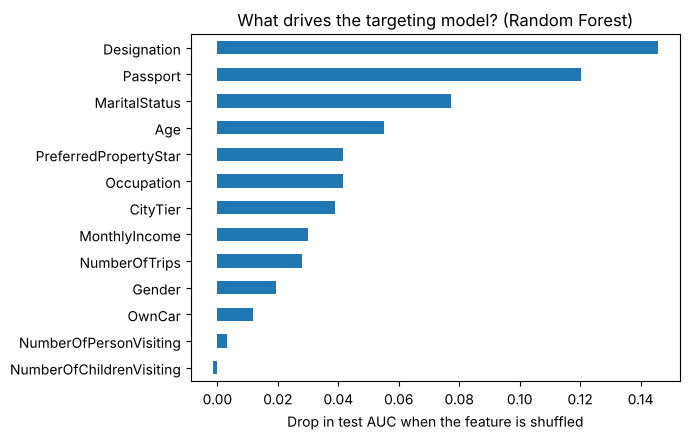

In [22]:
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance

models = {
    "Logistic (Model A)": pipe_A,
    "Random Forest": Pipeline([("prep", clone(prep_A)),
        ("clf", RandomForestClassifier(n_estimators=500, min_samples_leaf=3,
                                       class_weight="balanced_subsample",
                                       n_jobs=-1, random_state=42))]),
    "Gradient Boosting": Pipeline([("prep", clone(prep_A)),
        ("clf", HistGradientBoostingClassifier(learning_rate=0.05, max_depth=4,
                                               max_iter=300, class_weight="balanced",
                                               random_state=42))]),
}

rows, fitted = [], {}
for name, pipe in models.items():
    cvs = cross_val_score(pipe, XA_train, y_train, cv=cv, scoring="roc_auc")
    pipe.fit(XA_train, y_train)
    fitted[name] = pipe
    p_tr = pipe.predict_proba(XA_train)[:, 1]
    p = pipe.predict_proba(XA_test)[:, 1]
    rows.append({"model": name,
                 "CV_AUC": f"{cvs.mean():.3f} +/- {cvs.std():.3f}",
                 "Train_AUC": round(roc_auc_score(y_train, p_tr), 3),
                 "Test_AUC": round(roc_auc_score(y_test, p), 3),
                 "Test_AP": round(average_precision_score(y_test, p), 3),
                 "buyers_in_top20%": round(top_share(y_test, p, .2), 3),
                 "buyers_in_top40%": round(top_share(y_test, p, .4), 3)})
print(pd.DataFrame(rows).to_string(index=False))

# Which raw features matter most? (shuffle one column, see how much AUC drops)
best_name = max(rows, key=lambda r: float(r["CV_AUC"].split()[0]))["model"]
print("\nBest by cross-validated AUC:", best_name)
perm = permutation_importance(fitted[best_name], XA_test, y_test,
                              scoring="roc_auc", n_repeats=10,
                              random_state=42, n_jobs=-1)
imp = pd.Series(perm.importances_mean, index=XA_test.columns).sort_values()
print("\n=== PERMUTATION IMPORTANCE (AUC drop when shuffled) ===")
print(imp.sort_values(ascending=False).round(4))

plt.figure(figsize=(7, 4.5))
imp.plot(kind="barh")
plt.xlabel("Drop in test AUC when the feature is shuffled")
plt.title(f"What drives the targeting model? ({best_name})")
plt.tight_layout()
plt.show()

**Inference (model comparison)**
- Logistic regression: CV AUC **0.804**, test 0.749.
- Random Forest: CV AUC **0.895**, test **0.885**. Gradient Boosting: CV 0.861, test 0.826.
- The Random Forest is best, but its train AUC is 0.993, so we must check it is not just memorising.
- Top clues for the forest: **Designation, Passport, MaritalStatus, Age**.

> **In simple words:** a forest of many small decision trees can spot combinations a straight line cannot.

---
## Part 10: Check for repeated customers (leakage)
If the same customer profile appears in both train and test, the model may look better by remembering them.

In [23]:
# Build a text key from every pre-contact column (blanks marked as -1)
def key(d):
    return d.fillna(-1).astype(str).agg("|".join, axis=1)

ktr, kte = key(XA_train), key(XA_test)

# 1) How many test customers have an identical profile in the training set?
in_train = kte.isin(set(ktr)).values
print(f"Test customers whose exact profile also appears in train: "
      f"{in_train.sum()} of {len(kte)} ({in_train.mean() * 100:.1f}%)")

# 2) Duplicate profiles inside train: do they share the same label?
g = pd.DataFrame({"k": ktr.values, "y": y_train.values}).groupby("k")["y"]
dup = g.agg(["size", "mean"]).query("size > 1")
print(f"Duplicate-profile groups in train: {len(dup)} "
      f"(covering {int(dup['size'].sum())} rows)")
if len(dup):
    same = ((dup["mean"] == 0) | (dup["mean"] == 1)).mean()
    print(f"Share of those groups where everyone has the same label: {same:.1%}")

# 3) AUC separately for 'profile seen in train' and 'brand-new profile'
rows = []
for name in ["Logistic (Model A)", "Random Forest", "Gradient Boosting"]:
    p = fitted[name].predict_proba(XA_test)[:, 1]
    for mask, label in [(in_train, "profile seen in train"),
                        (~in_train, "brand-new profile")]:
        if mask.sum() > 20 and len(set(y_test.values[mask])) == 2:
            rows.append({"model": name, "test_rows": label, "n": int(mask.sum()),
                         "buyers": int(y_test.values[mask].sum()),
                         "AUC": round(roc_auc_score(y_test.values[mask], p[mask]), 3)})
print()
print(pd.DataFrame(rows).to_string(index=False))

Test customers whose exact profile also appears in train: 61 of 978 (6.2%)
Duplicate-profile groups in train: 158 (covering 316 rows)
Share of those groups where everyone has the same label: 100.0%

             model             test_rows   n  buyers   AUC
Logistic (Model A) profile seen in train  61      14 0.813
Logistic (Model A)     brand-new profile 917     170 0.743
     Random Forest profile seen in train  61      14 0.968
     Random Forest     brand-new profile 917     170 0.878
 Gradient Boosting profile seen in train  61      14 0.865
 Gradient Boosting     brand-new profile 917     170 0.823


**Inference (duplicate profiles)**
- **61 of 978 test customers (6.2%)** have an exact twin in the training data, and in every repeated group (**158 groups**) all customers had the **same answer**.
- On twins the forest scores AUC 0.968, but on **brand-new profiles** it scores **0.878**. The score is still good, just a little lower than it looked.
- From now on we use **grouped cross-validation**: customers with the same profile always stay together in the practice split.

> **In simple words:** if the exam has the same question as the homework, you do better. We keep repeated questions together so the score is honest.

In [24]:
from sklearn.model_selection import GroupKFold, cross_val_predict

groups = ktr.values                    # identical profiles stay in the same fold
gcv = GroupKFold(n_splits=5)

# Honest CV AUC (twins are never split across folds)
print("=== GROUPED CV AUC ===")
for name, pipe in models.items():
    s = cross_val_score(pipe, XA_train, y_train, cv=gcv, groups=groups,
                        scoring="roc_auc")
    print(f"{name:20s} {s.mean():.3f} +/- {s.std():.3f}")

=== GROUPED CV AUC ===


Logistic (Model A)   0.804 +/- 0.010


Random Forest        0.892 +/- 0.011


Gradient Boosting    0.865 +/- 0.019


**Inference (grouped cross-validation)**
- Honest scores: Logistic **0.804**, Random Forest **0.892**, Gradient Boosting **0.865**. The Random Forest is still the winner, so the lead is real.

> **In simple words:** even with repeats handled fairly, the forest wins.

---
## Part 11: Tune the Random Forest
We try a small set of settings and choose by grouped CV only (the test set is not touched).

In [25]:
# Small grid for the Random Forest, chosen by grouped CV (the test set is NOT used)
grid = [(leaf, mf) for leaf in [1, 2] for mf in ["sqrt", 0.3, 0.5]]
rows = []
for leaf, mf in grid:
    p = Pipeline([("prep", clone(prep_A)),
                  ("clf", RandomForestClassifier(
                      n_estimators=500, min_samples_leaf=leaf, max_features=mf,
                      class_weight="balanced_subsample", n_jobs=-1,
                      random_state=42))])
    s = cross_val_score(p, XA_train, y_train, cv=gcv, groups=groups,
                        scoring="roc_auc")
    rows.append({"min_samples_leaf": leaf, "max_features": mf,
                 "grouped_CV_AUC": round(s.mean(), 4), "std": round(s.std(), 4)})
tune = pd.DataFrame(rows).sort_values("grouped_CV_AUC", ascending=False)
print(tune.to_string(index=False))
best = tune.iloc[0]

# Fit the best setting on the training set
mf = best["max_features"]
mf = float(mf) if mf not in ("sqrt", "log2") else mf
rf2 = Pipeline([("prep", clone(prep_A)),
                ("clf", RandomForestClassifier(
                    n_estimators=500, min_samples_leaf=int(best["min_samples_leaf"]),
                    max_features=mf, class_weight="balanced_subsample",
                    n_jobs=-1, random_state=42))])
rf2.fit(XA_train, y_train)

 min_samples_leaf max_features  grouped_CV_AUC    std
                1          0.5          0.9231 0.0082
                1          0.3          0.9198 0.0104
                1         sqrt          0.9180 0.0099
                2          0.5          0.9107 0.0097
                2          0.3          0.9063 0.0108
                2         sqrt          0.9018 0.0118


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](13,)","['Age','CityTier','Occupation',...,'NumberOfChildrenVisiting', 'Designation','MonthlyIncome']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,13
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('bin', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='pas

**Inference (best settings)**
- Best settings: `min_samples_leaf = 1`, `max_features = 0.5` with grouped CV AUC **0.923**.
- Letting trees grow fully works better here than forcing bigger leaves.

> **In simple words:** like trying a few recipes and keeping the one that tastes best in the practice rounds.

---
## Part 12: Pick the final model
We add a few **new clues** built from existing columns, and compare tree types with repeated grouped CV. A difference counts as real only if it is more than **2 x its standard error**.

In [26]:
import importlib

# A small module holds the feature builder and the scorer, so the saved model
# can be loaded in any session (not only in this notebook).
module_code = '''
import numpy as np
import pandas as pd


def add_feats(d):
    """Row-wise features built from pre-contact customer columns."""
    d = d.copy()
    single = (d["MaritalStatus"] == "Single").astype(int)
    execu = (d["Designation"] == "Executive").astype(int)
    d["Exec_Passport_Single"] = execu * d["Passport"] * single
    d["Passport_Single"] = d["Passport"] * single
    d["Exec_Passport"] = execu * d["Passport"]
    persons = d["NumberOfPersonVisiting"].replace(0, np.nan)
    d["Income_per_Person"] = d["MonthlyIncome"] / persons
    d["Kids_Share"] = d["NumberOfChildrenVisiting"] / persons
    d["Trips_per_Age"] = d["NumberOfTrips"] / d["Age"].replace(0, np.nan)
    return d


def score_customers(new_df, art):
    """Return a score and a priority tier (A, B or C) for each customer."""
    X_new = new_df[art["features"]]
    score = art["model"].predict_proba(X_new)[:, 1]
    tier = np.where(score >= art["cutoffs"]["A"], "A (top 10%)",
           np.where(score >= art["cutoffs"]["B"], "B (next 20%)", "C (low)"))
    return pd.DataFrame({"score": score.round(3), "priority": tier},
                        index=new_df.index)
'''
with open("wellness_features.py", "w") as f:
    f.write(module_code)

import wellness_features
importlib.reload(wellness_features)
from wellness_features import add_feats
print("Feature module written: wellness_features.py")

Feature module written: wellness_features.py


**Inference (new clues)**
- New columns: `Exec_Passport_Single` (Executive + passport + single), `Passport_Single`, `Exec_Passport`, `Income_per_Person`, `Kids_Share`, `Trips_per_Age`.
- They are saved in a small file `wellness_features.py` so the same code is used when we score new customers later.

> **In simple words:** we write down the best 'combo clues' we found in the exploration so the model does not have to discover them alone.

In [27]:
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import FunctionTransformer
from sklearn.ensemble import ExtraTreesClassifier

# Columns for the version that includes the new features
num_B = num_A + ["Income_per_Person", "Kids_Share", "Trips_per_Age"]
bin_B = bin_A + ["Exec_Passport_Single", "Passport_Single", "Exec_Passport"]
prep_B = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                      ("sc", StandardScaler())]), num_B),
    ("bin", SimpleImputer(strategy="most_frequent"), bin_B),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("oh", OneHotEncoder(drop="first",
                                           handle_unknown="ignore"))]), cat_A),
])


def with_feats(clf):
    """Pipeline that first adds the new features."""
    return Pipeline([("fe", FunctionTransformer(add_feats)),
                     ("prep", clone(prep_B)), ("clf", clf)])


def plain(clf):
    """Pipeline on the original 13 features."""
    return Pipeline([("prep", clone(prep_A)), ("clf", clf)])


def forest(kind, mf):
    cls = ExtraTreesClassifier if kind == "et" else RandomForestClassifier
    return cls(n_estimators=500, min_samples_leaf=1, max_features=mf,
               class_weight="balanced_subsample", n_jobs=-1, random_state=42)


cands = {
    "A. Random Forest (tuned)":                 clone(rf2),
    "B. Random Forest + new features":          with_feats(forest("rf", 0.5)),
    "C. ExtraTrees, original, mf 0.5":          plain(forest("et", 0.5)),
    "D. ExtraTrees, original, mf 0.8":          plain(forest("et", 0.8)),
    "E. ExtraTrees + new features, mf 0.5":     with_feats(forest("et", 0.5)),
    "F. ExtraTrees + new features, mf 0.8":     with_feats(forest("et", 0.8)),
}

# 3 x 5-fold grouped CV: identical profiles are never split across folds
recs = []
for seed in [0, 1, 2]:
    sgk = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)
    for fold, (tr, va) in enumerate(sgk.split(XA_train, y_train, groups)):
        Xa, Xb = XA_train.iloc[tr], XA_train.iloc[va]
        ya, yb = y_train.iloc[tr], y_train.iloc[va]
        for name, m in cands.items():
            p = clone(m).fit(Xa, ya).predict_proba(Xb)[:, 1]
            recs.append({"run": f"{seed}-{fold}", "model": name,
                         "auc": roc_auc_score(yb, p),
                         "ap": average_precision_score(yb, p),
                         "top20": top_share(yb, p, .2),
                         "top40": top_share(yb, p, .4)})
R = pd.DataFrame(recs)


# Paired difference against a reference model (same folds)
def paired(ref):
    base = R[R.model == ref].set_index("run")["auc"]
    out = {}
    for name, g in R.groupby("model"):
        d = g.set_index("run")["auc"] - base
        out[name] = (d.mean(), d.std(ddof=1) / np.sqrt(len(d)))
    return out


vs_A = paired("A. Random Forest (tuned)")
vs_F = paired("F. ExtraTrees + new features, mf 0.8")
rows = []
for name, g in R.groupby("model"):
    rows.append({"model": name, "auc": g.auc.mean(), "ap": g.ap.mean(),
                 "buyers_top20%": g.top20.mean(), "buyers_top40%": g.top40.mean(),
                 "diff_vs_A": vs_A[name][0], "se_vs_A": vs_A[name][1],
                 "diff_vs_F": vs_F[name][0], "se_vs_F": vs_F[name][1]})
display(pd.DataFrame(rows).set_index("model").round(4))
print("A difference is real only if it is more than 2 x its standard error.")

,auc,ap,buyers_top20%,buyers_top40%,diff_vs_A,se_vs_A,diff_vs_F,se_vs_F
model,,,,,,,,
A. Random Forest (tuned),0.9042,0.7272,0.7260,0.9058,0.0000,0.0000,-0.0190,0.0027
B. Random Forest + new features,0.8994,0.7246,0.7201,0.9017,-0.0048,0.0014,-0.0238,0.0023
"C. ExtraTrees, original, mf 0.5",0.9157,0.7472,0.7346,0.9194,0.0115,0.0023,-0.0075,0.0015
"D. ExtraTrees, original, mf 0.8",0.9139,0.7405,0.7255,0.9167,0.0096,0.0026,-0.0094,0.0019
"E. ExtraTrees + new features, mf 0.5",0.9211,0.7587,0.7355,0.9275,0.0169,0.0025,-0.0021,0.0007
"F. ExtraTrees + new features, mf 0.8",0.9232,0.7640,0.7386,0.9302,0.0190,0.0027,0.0000,0.0000


A difference is real only if it is more than 2 x its standard error.


**Inference (final choice)**
- Random Forest + new features did **not** help (-0.005). But **ExtraTrees** (a more random cousin of the forest) with the new clues did: AUC **0.923** vs **0.904** for the tuned forest.
- The gain of **+0.019** is about **7 times its standard error (0.0027)**, so it is real, not luck.
- **Final model: ExtraTrees + new features, `max_features = 0.8`.**

> **In simple words:** the best model is a team of very random trees that are also told the best combo clues.

---
## Part 13: The final exam: test the chosen model once
Now we open the locked test set one time and build priority groups.

In [28]:
# ---- 1. Final model: ExtraTrees + new features, max_features = 0.8 ----
final_model = with_feats(forest("et", 0.8))
final_model.fit(XA_train, y_train)
p_final = final_model.predict_proba(XA_test)[:, 1]
p_rf = rf2.predict_proba(XA_test)[:, 1]

# ---- 2. ONE look at the test set: tuned Random Forest vs final model ----
rows = []
for name, p in [("Random Forest (tuned)", p_rf), ("ExtraTrees + features (final)", p_final)]:
    rows.append({"model": name,
                 "AUC": roc_auc_score(y_test, p),
                 "AP": average_precision_score(y_test, p),
                 "buyers_top20%": top_share(y_test, p, .2),
                 "buyers_top40%": top_share(y_test, p, .4),
                 "AUC brand-new profiles": roc_auc_score(
                     y_test.values[~in_train], p[~in_train])})
display(pd.DataFrame(rows).set_index("model").round(3))

# ---- 3. Priority tiers: cut-offs from grouped out-of-fold TRAIN scores ----
oof_final = cross_val_predict(clone(final_model), XA_train, y_train, cv=gcv,
                              groups=groups, method="predict_proba")[:, 1]
cuts = {"A": float(np.quantile(oof_final, 0.90)),
        "B": float(np.quantile(oof_final, 0.70))}
print("Cut-offs:", {k: round(v, 3) for k, v in cuts.items()})

tier = np.where(p_final >= cuts["A"], "A (top 10%)",
       np.where(p_final >= cuts["B"], "B (next 20%)", "C (low)"))
rep = (pd.DataFrame({"tier": tier, "bought": y_test.values})
       .groupby("tier")["bought"].agg(customers="size", buyers="sum",
                                      buy_rate="mean"))
rep["share_of_all_buyers_%"] = (rep["buyers"] / y_test.sum() * 100).round(1)
display(rep.round(3))

# ---- 4. How much could the test AUC move by chance? (bootstrap) ----
rng = np.random.default_rng(42)
boot = []
for _ in range(1000):
    idx = rng.integers(0, len(y_test), len(y_test))
    if len(set(y_test.values[idx])) < 2:
        continue
    boot.append(roc_auc_score(y_test.values[idx], p_final[idx]))
print("Test AUC 95% range: {:.3f} to {:.3f}".format(*np.percentile(boot, [2.5, 97.5])))

,AUC,AP,buyers_top20%,buyers_top40%,AUC brand-new profiles
model,,,,,
Random Forest (tuned),0.923,0.815,0.750,0.902,0.915
ExtraTrees + features (final),0.957,0.872,0.804,0.962,0.950


Cut-offs: {'A': 0.67, 'B': 0.161}


,customers,buyers,buy_rate,share_of_all_buyers_%
tier,,,,
A (top 10%),101,95,0.941,51.6
B (next 20%),165,68,0.412,37.0
C (low),712,21,0.029,11.4


Test AUC 95% range: 0.943 to 0.970


**Inference (test result and priority groups)**
- Test AUC **0.957** (old forest 0.923). On **brand-new profiles** it is **0.950** (old forest 0.915). Of all buyers, **80.4%** sit in the top 20% of the list and **96.2%** in the top 40%.
- **Group A (top 10%)**: 101 customers, **95 bought (94.1%)**, holding **51.6% of all buyers**.
- **Group B (next 20%)**: 165 customers, 68 bought (41.2%), another 37.0% of buyers.
- **Group C (rest)**: 712 customers, only 21 bought (2.9%). Calling them first would waste time.
- The 95% range for test AUC is **0.943 to 0.970**, so the score is stable even if the exam were slightly different.

> **In simple words:** if the team calls only groups A and B (27% of customers), they win about 9 out of 10 buyers.

In [29]:
PROFIT_TO_COST = 10      # EDIT: profit from one sale / cost of one contact


def top_table(y, p, ratio):
    """Contact the top X% of customers: buyers found, hit rate, net value."""
    y = np.asarray(y); order = np.argsort(-p); rows = []
    for f in np.arange(0.1, 1.01, 0.1):
        k = int(round(len(y) * f)); hit = y[order[:k]]
        rows.append({"contact_top_%": int(round(f * 100)),
                     "buyers_found_%": round(hit.sum() / y.sum() * 100, 1),
                     "hit_rate_%": round(hit.mean() * 100, 1),
                     "net_value_per_customer": round(
                         (hit.sum() * ratio - k) / len(y), 3)})
    return pd.DataFrame(rows)


print(f"=== TEST: contact the top X% (profit/cost = {PROFIT_TO_COST}) ===")
print(top_table(y_test, p_final, PROFIT_TO_COST).to_string(index=False))

# Best contact share for different profit/cost ratios (chosen on train OOF)
print("\n=== BEST CONTACT SHARE BY PROFIT/COST RATIO ===")
for r in [3, 5, 10, 20, 50]:
    t = top_table(y_train, oof_final, r)
    best_row = t.loc[t["net_value_per_customer"].idxmax()]
    tt = top_table(y_test, p_final, r)
    on_test = tt[tt["contact_top_%"] == best_row["contact_top_%"]].iloc[0]
    print(f"ratio {r:3d}: contact top {int(best_row['contact_top_%'])}% -> "
          f"test net value {on_test['net_value_per_customer']:.3f} "
          f"(contact everyone: {tt.iloc[-1]['net_value_per_customer']:.3f})")

=== TEST: contact the top X% (profit/cost = 10) ===
 contact_top_%  buyers_found_%  hit_rate_%  net_value_per_customer
            10            50.0        93.9                   0.840
            20            80.4        75.5                   1.313
            30            92.4        58.0                   1.439
            40            96.2        45.3                   1.410
            50            98.4        37.0                   1.351
            60            99.5        31.2                   1.271
            70           100.0        26.9                   1.181
            80           100.0        23.5                   1.082
            90           100.0        20.9                   0.982
           100           100.0        18.8                   0.881

=== BEST CONTACT SHARE BY PROFIT/COST RATIO ===
ratio   3: contact top 20% -> test net value 0.254 (contact everyone: -0.436)
ratio   5: contact top 30% -> test net value 0.570 (contact everyone: -0.059)
ratio 

**Inference (how many to call)**
- If each sale earns **10 times** what a call costs, calling the **top 30%** finds **92.4% of buyers** with a **58% hit rate**, and gives the best profit per customer (1.44, against 0.88 for calling everyone).
- If a sale only earns 3 times the call cost, the best choice is the **top 20%**, and calling everyone **loses money**.
- Change `PROFIT_TO_COST` to match your own numbers.

> **In simple words:** call fewer, better people: the sales team saves effort and makes more money.

---
## Part 14: Is the model overfitting or cheating?
A good score is only useful if it is honest. We check three things.

Train AUC            : 1.000
Grouped CV AUC (OOF) : 0.935
Test AUC             : 0.957


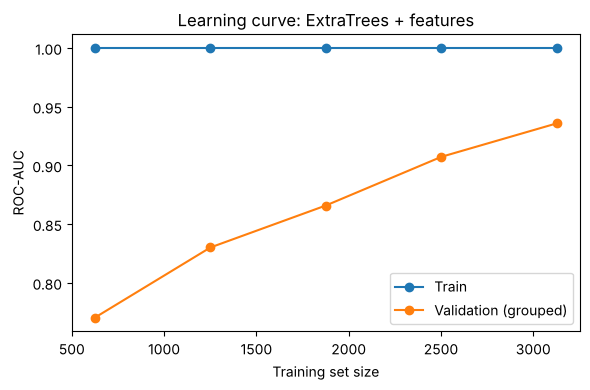

Last point -> train 1.000 | validation 0.936



min_samples_leaf | Train | Validation (grouped)
               1 | 1.000 | 0.936
               2 | 1.000 | 0.926
               3 | 0.999 | 0.919
               5 | 0.991 | 0.908
              10 | 0.961 | 0.890



Shuffled-label grouped CV AUC: 0.515 (about 0.50 means no leakage)


In [30]:
from sklearn.model_selection import learning_curve, validation_curve

# ---- 1. Train vs grouped-CV vs test AUC for the final model ----
p_tr = final_model.predict_proba(XA_train)[:, 1]
print("Train AUC            : {:.3f}".format(roc_auc_score(y_train, p_tr)))
print("Grouped CV AUC (OOF) : {:.3f}".format(roc_auc_score(y_train, oof_final)))
print("Test AUC             : {:.3f}".format(roc_auc_score(y_test, p_final)))

# ---- 2. Learning curve with grouped folds (does more data help?) ----
sizes, tr_s, va_s = learning_curve(
    clone(final_model), XA_train, y_train, groups=groups, cv=gcv,
    scoring="roc_auc", n_jobs=-1, train_sizes=np.linspace(0.2, 1.0, 5))
plt.figure(figsize=(6, 4))
plt.plot(sizes, tr_s.mean(axis=1), "o-", label="Train")
plt.plot(sizes, va_s.mean(axis=1), "o-", label="Validation (grouped)")
plt.xlabel("Training set size")
plt.ylabel("ROC-AUC")
plt.title("Learning curve: ExtraTrees + features")
plt.legend()
plt.tight_layout()
plt.show()
print("Last point -> train {:.3f} | validation {:.3f}".format(
    tr_s.mean(axis=1)[-1], va_s.mean(axis=1)[-1]))

# ---- 3. Simpler trees: does validation get better or worse? ----
vals = [1, 2, 3, 5, 10]
tr_v, va_v = validation_curve(
    clone(final_model), XA_train, y_train, groups=groups, cv=gcv,
    param_name="clf__min_samples_leaf", param_range=vals,
    scoring="roc_auc", n_jobs=-1)
print("\nmin_samples_leaf | Train | Validation (grouped)")
for v, a, b in zip(vals, tr_v.mean(axis=1), va_v.mean(axis=1)):
    print(f"{v:16d} | {a:.3f} | {b:.3f}")

# ---- 4. Leakage check: shuffle the labels, AUC should fall to about 0.5 ----
rng = np.random.default_rng(0)
y_shuf = pd.Series(rng.permutation(y_train.values), index=y_train.index)
s = cross_val_score(clone(final_model), XA_train, y_shuf, groups=groups,
                    cv=gcv, scoring="roc_auc", n_jobs=-1)
print("\nShuffled-label grouped CV AUC: {:.3f} (about 0.50 means no leakage)"
      .format(s.mean()))

**Inference (overfit and leakage checks)**
- Train AUC is **1.000**, grouped CV **0.935** and test **0.957**. The gap between train and CV shows **mild overfitting**, which is normal for forests, and CV and test are close, so it still works on new customers.
- The learning curve is still rising, so **more data** would help a little.
- Trying bigger leaves lowers train score but **also lowers** the validation score, so we keep the settings that do best on unseen customers.
- **Shuffled-label check:** when we scramble the answers, AUC drops to **0.515** (about 0.50). If there were leakage it would stay high. So there is **no leakage**.
- A safe number to quote is the **grouped CV AUC (about 0.93)**. The 0.957 test score is slightly lucky.

> **In simple words:** the model learned real patterns, not tricks. Practice (0.935) and exam (0.957) agree, and scrambling the answers breaks it, as it should.

---
## Part 15: Who exactly should we target?
We describe the top 30% in plain words using charts and a very small decision tree.

Score cut-off for the top 30%: 0.161
                  customers  buyers  buy_rate
target                                       
Others                 3449      96     0.028
Target (top 30%)       1439     824     0.573


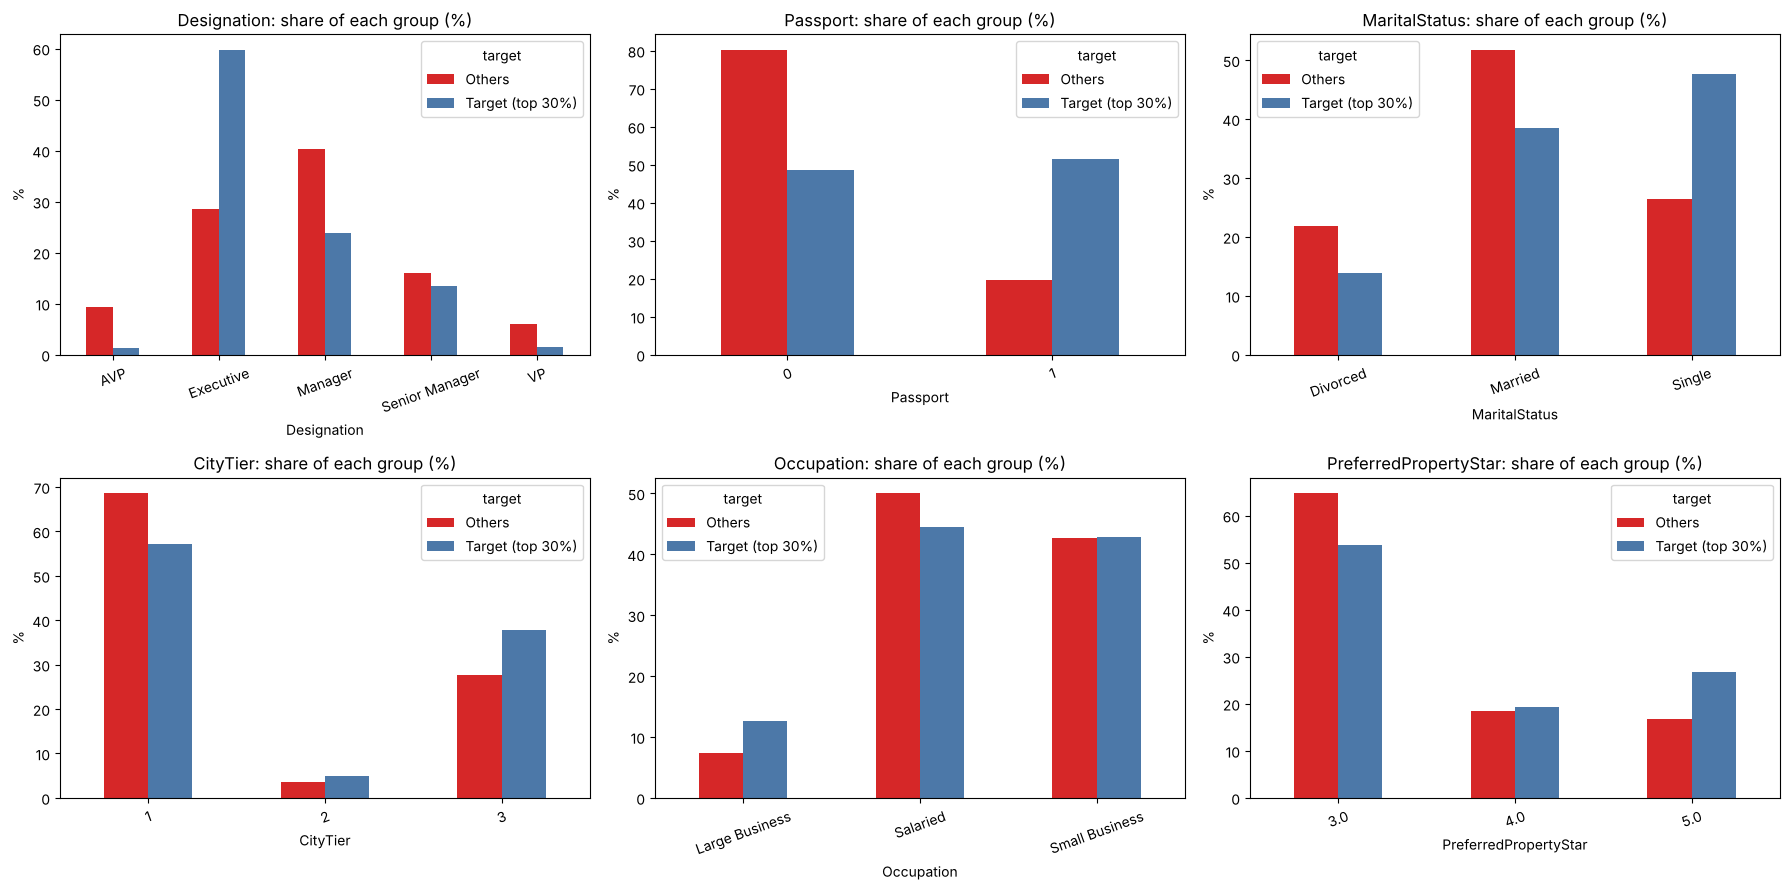


=== AVERAGES: TARGET vs OTHERS ===
target           Others  Target (top 30%)
Age               38.82             34.69
MonthlyIncome  24288.65          21962.87
NumberOfTrips      3.23              3.22
Passport           0.20              0.51

=== SIMPLE RULES (decision tree, depth 3) ===
|--- bin__Passport <= 0.50
|   |--- num__Age <= -1.76
|   |   |--- class: 0
|   |--- num__Age >  -1.76
|   |   |--- num__PreferredPropertyStar <= 1.15
|   |   |   |--- class: 0
|   |   |--- num__PreferredPropertyStar >  1.15
|   |   |   |--- class: 0
|--- bin__Passport >  0.50
|   |--- cat__Designation_Executive <= 0.50
|   |   |--- cat__CityTier_3 <= 0.50
|   |   |   |--- class: 0
|   |   |--- cat__CityTier_3 >  0.50
|   |   |   |--- class: 0
|   |--- cat__Designation_Executive >  0.50
|   |   |--- cat__MaritalStatus_Single <= 0.50
|   |   |   |--- class: 0
|   |   |--- cat__MaritalStatus_Single >  0.50
|   |   |   |--- class: 1


=== LEAVES (groups) ranked by buy rate ===
      customers  buy_rat

In [31]:
from sklearn.tree import DecisionTreeClassifier, export_text

# Scores from the FINAL model: out-of-fold for train, model score for test
oof, p_test = oof_final, p_final
all_X = pd.concat([XA_train, XA_test])
all_df = all_X.assign(score=np.r_[oof, p_test],
                      y=np.r_[y_train.values, y_test.values])
cutoff = np.quantile(oof, 0.70)           # top 30% by training scores
all_df["target"] = (all_df["score"] >= cutoff).map({True: "Target (top 30%)",
                                                    False: "Others"})
print(f"Score cut-off for the top 30%: {cutoff:.3f}")
print(all_df.groupby("target")["y"].agg(customers="size", buyers="sum",
                                        buy_rate="mean").round(3))

# Who are they? Share of each group inside Target vs Others
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, c in zip(axes.ravel(),
                 ["Designation", "Passport", "MaritalStatus",
                  "CityTier", "Occupation", "PreferredPropertyStar"]):
    s = (pd.crosstab(all_df[c], all_df["target"], normalize="columns") * 100)
    s.plot(kind="bar", ax=ax, color=["#d62728", "#4C78A8"])
    ax.set_title(f"{c}: share of each group (%)")
    ax.set_ylabel("%")
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

print("\n=== AVERAGES: TARGET vs OTHERS ===")
print(all_df.groupby("target")[["Age", "MonthlyIncome", "NumberOfTrips",
                                "Passport"]].mean().round(2).T)

# Simple rules: a small decision tree on the same pre-contact features
prep_tree = clone(prep_A).fit(XA_train)
tnames = prep_tree.get_feature_names_out()
tree = DecisionTreeClassifier(max_depth=3, min_samples_leaf=40, random_state=42)
tree.fit(prep_tree.transform(XA_train), y_train)
print("\n=== SIMPLE RULES (decision tree, depth 3) ===")
print(export_text(tree, feature_names=list(tnames)))

leaf = tree.apply(prep_tree.transform(XA_train))
lt = (pd.DataFrame({"leaf": leaf, "y": y_train.values}).groupby("leaf")["y"]
      .agg(customers="size", buy_rate="mean").round(3)
      .sort_values("buy_rate", ascending=False))
print("\n=== LEAVES (groups) ranked by buy rate ===")
print(lt.to_string())

**Inference (target group)**
- The target group (top 30%, **1,439 customers**) has **824 buyers (57.3% buy rate)**; the others (3,449 customers) have only **96 buyers (2.8%)**.
- Targets are **younger** (34.7 vs 38.8 years) and **half have a passport** (51% vs 20%).
- Simple rule from the small tree: **Passport + Executive + Single -> likely buyer** (the best leaf buys **74%**). The biggest low group (2,180 customers, no passport and few other signs) buys only **8.9%**.

> **In simple words:** call young, single, executive-level customers who own a passport first.

---
## Part 16: Save the model and score new customers
We save the model, the group cut-offs and the feature list so the team can reuse them. We reload it and check that it gives the same scores.

In [32]:
import joblib
from wellness_features import score_customers

# Save the model with its cut-offs and the list of columns it needs
joblib.dump({"model": final_model, "cutoffs": cuts,
             "features": list(XA_train.columns)},
            "wellness_package_et_v3.joblib")

# Reload it, check the scores are identical, and score the test customers
art = joblib.load("wellness_package_et_v3.joblib")
chk = art["model"].predict_proba(XA_test[art["features"]])[:, 1]
print("Reloaded scores identical:", np.allclose(chk, p_final))

res = score_customers(XA_test, art)
res["bought"] = y_test.values
print("\n=== TEST: PRIORITY TIERS (scored with the reloaded model) ===")
print(res.groupby("priority")["bought"].agg(customers="size", buyers="sum",
                                            buy_rate="mean").round(3))
res.head()

Reloaded scores identical: True

=== TEST: PRIORITY TIERS (scored with the reloaded model) ===
              customers  buyers  buy_rate
priority                                 
A (top 10%)         101      95     0.941
B (next 20%)        165      68     0.412
C (low)             712      21     0.029


,score,priority,bought
3006,1.000,A (top 10%),1
773,0.036,C (low),0
4623,0.384,B (next 20%),1
3787,0.254,B (next 20%),0
576,0.000,C (low),0


**Inference (saved model)**
- The reloaded model gives **identical scores**, so the saved file is trustworthy.
- New customers can be scored with `score_customers(new_df, art)`; it returns a score and a priority group (A / B / C).

> **In simple words:** we put the finished model in a box so anyone can use it tomorrow without training again.

---
## Summary

| Question | Answer |
|---|---|
| **What did we build?** | A model that ranks customers by how likely they are to buy the Wellness Package, using only facts known **before** the call |
| **Final model** | ExtraTrees + 6 new clue columns (`max_features = 0.8`) |
| **How good is it?** | Test AUC **0.957** (95% range 0.943-0.970); honest grouped-CV AUC about **0.93**; old simple model was 0.75 |
| **Group A (top 10%)** | 94% of them buy and they hold half of all buyers |
| **Group A + B (top 30%)** | They hold about **89%** of all buyers; Group C (70% of customers) holds about 11% |
| **Biggest clues** | Passport, job level (Executive), marital status (Single), age, City Tier 3, follow-up calls |
| **Is it safe?** | No leakage found (shuffled-label AUC 0.515); mild overfitting only; repeated customers handled with grouped CV |
| **What next?** | Collect more customers (learning curve still rising); re-train every few months; test the plan with a small pilot call campaign |

**One-sentence conclusion:** call young, single, executive-level customers with a passport first; this simple plan reaches most buyers while calling far fewer people.

*Numbers can change by about 0.01 when you re-run on another computer or library version.*